# Join of the dastasets

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut

hd_df = pd.read_csv("../../data/processed/hd.csv")
lab_events_df = pd.read_csv("../../data/processed/lab_events.csv")
micro_bio_df = pd.read_csv("../../data/processed/microbio.csv")
procedures_df = pd.read_csv("../../data/processed/procedure_code_summary.csv")

# Make the join between processed datasets

joined_df = pd.merge(hd_df, lab_events_df, on='hadm_id', how='left', suffixes=('_hd', '_le'))

joined_df = pd.merge(
    joined_df,
    micro_bio_df,
    on=['subject_id', 'hadm_id'],
    how='left',
    suffixes=('_joined', '_micro')
)

joined_df = pd.merge(
    joined_df,
    procedures_df,
    on=['subject_id', 'hadm_id'],
    how='left',
    suffixes=('_joined', '_proc')
)

# Drop ALL duplicate rows (keeps only unique rows)
joined_df = joined_df.drop_duplicates().reset_index(drop=True)

In [2]:
# For each ICD code, use only the numeric part
joined_df['icd_code_joined'] = joined_df['icd_code_joined'].apply(lambda x: np.int64(str(x).split('I')[1]) if pd.notnull(x) else x)
joined_df

,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,50,Heart failure,F,75.0,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10000980,29654838,50,Heart failure,F,75.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10000980,29654838,50,Heart failure,F,75.0,2188-01-04 23:43:00,0.02,ng/mL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10000980,29654838,50,Heart failure,F,75.0,2188-01-05 06:56:00,1.20,u,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10000980,29654838,50,Heart failure,F,75.0,2188-01-05 06:56:00,73.00,sec,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4430900,19998600,21593455,35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4430901,19998600,21593455,35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,143.00,mg/dL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4430902,19998600,21593455,35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4430903,19998600,21593455,35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Mapping the gender in 0-1 (0: male , 1: female)
joined_df['gender'] = joined_df['gender'].apply(lambda x: 1 if x == 'F' else 0)
joined_df

,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,0.02,ng/mL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10000980,29654838,50,Heart failure,1,75.0,2188-01-05 06:56:00,1.20,u,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10000980,29654838,50,Heart failure,1,75.0,2188-01-05 06:56:00,73.00,sec,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4430900,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4430901,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,143.00,mg/dL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4430902,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4430903,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


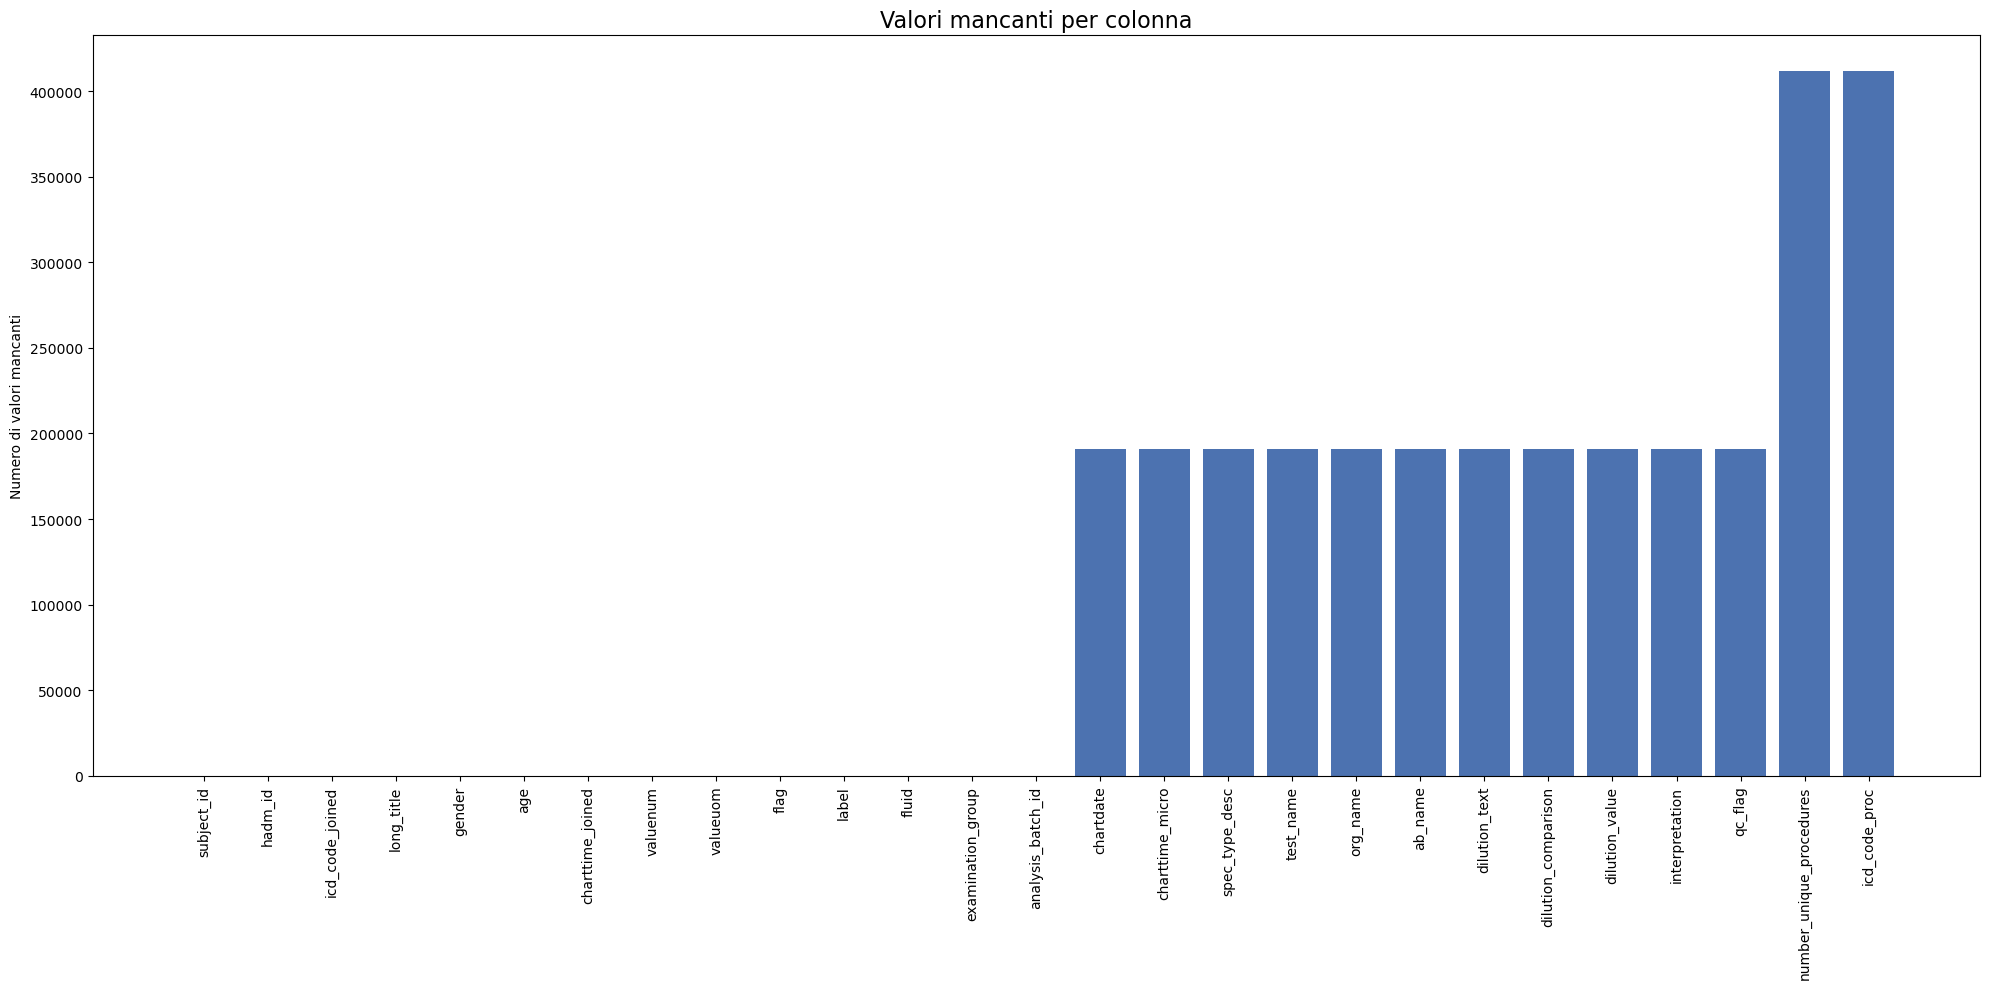

In [4]:

plt.figure(figsize=(20,10))

# Conteggio dei NaN per colonna
missing_counts = joined_df.isnull().sum()

# Barplot
plt.bar(missing_counts.index, missing_counts.values, color="#4c72b0")

plt.title("Valori mancanti per colonna", fontsize=16)
plt.ylabel("Numero di valori mancanti")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [5]:


def count_null_entries(df):
    """
    Conta quanti valori nulli (NaN) ci sono per riga
    e restituisce la distribuzione in percentuale.
    """
    # Conta i NaN per ogni riga
    null_counts = df.isnull().sum(axis=1)

    # Distribuzione: quante righe hanno 0, 1, 2... NaN
    null_percentage = null_counts.value_counts().sort_index() / len(df) * 100

    # Restituisce un dataframe riassuntivo
    return null_percentage.reset_index().rename(
        columns={'index': 'Numero di valori null per riga',
                 0: 'Percentuale righe null'}
    )

# Uso sul tuo dataset
count_null_entries(joined_df)



,Numero di valori null per riga,count
0,0,87.881370
1,2,7.802808
2,8,0.000068
3,11,2.821184
4,13,1.494322
5,19,0.000068
6,21,0.000181


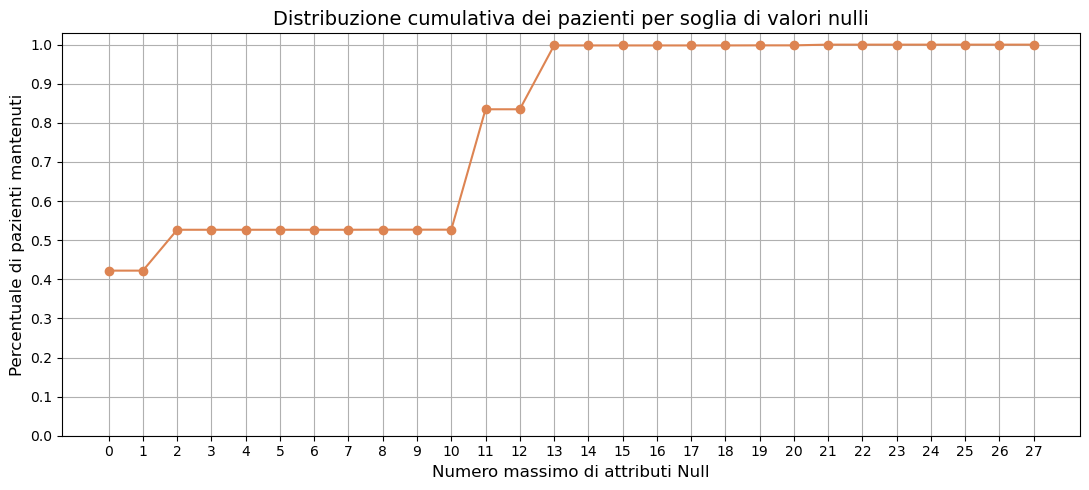

In [6]:


# Dizionario per salvare la percentuale cumulativa di pazienti
temp_pazienti = {}

# Totale pazienti unici nel dataset
totale_pazienti = joined_df["subject_id"].nunique()

# Loop su tutte le soglie da 0 a numero di colonne
for threshold in range(0, len(joined_df.columns)+1):
    # Maschera: righe con al massimo 'threshold' valori nulli
    mask = (joined_df.isnull().sum(axis=1)) <= threshold

    # Pazienti unici che rimarrebbero
    pazienti_mantenuti = joined_df[mask]["subject_id"].nunique()

    # Percentuale di pazienti mantenuti
    temp_pazienti[threshold] = pazienti_mantenuti / totale_pazienti

# Plot
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(list(temp_pazienti.keys()), list(temp_pazienti.values()), marker='o', color="#dd8452")

# Etichette e griglia
ax.set_xticks(range(0, len(joined_df.columns)+1, 1))
ax.set_yticks(np.arange(0, 1.1, 0.1))
ax.grid(True)
ax.set_xlabel("Numero massimo di attributi Null", fontsize=12)
ax.set_ylabel("Percentuale di pazienti mantenuti", fontsize=12)
ax.set_title("Distribuzione cumulativa dei pazienti per soglia di valori nulli", fontsize=14)
plt.tight_layout()
plt.show()


In [7]:
# Maschera: righe con più di 13 valori nulli DA SCEGLIERE CHE VALORE METTERE
mask_drop = joined_df.isnull().sum(axis=1) > 13

# Righe che verrebbero eliminate
rows_dropped = joined_df[mask_drop]

# Conteggio dei pazienti persi
num_pazienti_persi = rows_dropped["subject_id"].nunique()

# Percentuale sul totale
percentuale_persi = num_pazienti_persi /joined_df["subject_id"].nunique() * 100

print(f"Pazienti persi: {num_pazienti_persi} ({percentuale_persi:.2f}%)")


Pazienti persi: 11 (0.25%)


In [8]:
def drop_rows_with_nulls(df, threshold, ignore_cols=[]):
    """
    Elimina le righe che hanno più di 'threshold' valori nulli,
    ignorando le colonne specificate in 'ignore_cols'.
    """
    cols_to_check = [col for col in df.columns if col not in ignore_cols]
    min_non_nulls = len(cols_to_check) - threshold
    df_cleaned = df.dropna(thresh=min_non_nulls, subset=cols_to_check)
    return df_cleaned
joined_df = drop_rows_with_nulls(joined_df, threshold=13)

In [9]:
#Filling the missing values for those who did not have a lab event done
joined_df['valuenum'] = joined_df['valuenum'].fillna(value = -1)
joined_df['valueuom'] = joined_df['valueuom'].fillna(value = "NO_UOM")
joined_df['flag'] = joined_df['flag'].fillna(value = -1)
joined_df['label'] = joined_df['label'].fillna(value = "NO_LAB_LABEL")
joined_df['fluid'] = joined_df['fluid'].fillna(value = "NO_FLUID")
joined_df['examination_group'] = joined_df['examination_group'].fillna(value = "NO_EXAM_GROUP")
joined_df['analysis_batch_id'] = joined_df['analysis_batch_id'].fillna(value = "NO_BATCH_ID")

# Filling the missing values for those who did not have any procedure done
joined_df['number_unique_procedures'] = joined_df['number_unique_procedures'].fillna(value = 0)
joined_df['icd_code_proc'] = joined_df['icd_code_proc'].fillna(value = "NO_PROCEDURES")

joined_df

C:\Users\Cominotti\AppData\Local\Temp\ipykernel_20240\3232492386.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  joined_df['valuenum'] = joined_df['valuenum'].fillna(value = -1)
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_20240\3232492386.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  joined_df['valueuom'] = joined_df['valueuom'].fillna(value = "NO_UOM")
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_20240\3232492386.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a sli

,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
1,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
2,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,0.02,ng/mL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
3,10000980,29654838,50,Heart failure,1,75.0,2188-01-05 06:56:00,1.20,u,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
4,10000980,29654838,50,Heart failure,1,75.0,2188-01-05 06:56:00,73.00,sec,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4430900,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
4430901,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,143.00,mg/dL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
4430902,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
4430903,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES


In [10]:
# Filling the missing values for those who did not have a microbio test done
joined_df['spec_type_desc'] = joined_df['spec_type_desc'].fillna(value = "NO_MICROBIO")
joined_df

#If NO_MICROBIO, fill the microbio_test fields 
micro_bio_cols = ['org_name', 'ab_name', 'dilution_text','dilution_comparison','dilution_value', 'interpretation', 'qc_flag']

micro_bio_mask = joined_df['spec_type_desc'] == "NO_MICROBIO"

#Fill orgname with NOT_ORG_DETECTED
joined_df.loc[micro_bio_mask, 'org_name'] = joined_df.loc[micro_bio_mask, 'org_name'].fillna(value = "NO_ORG_DETECTED")

#Fill test_name with NO_TEST_DONE
joined_df.loc[micro_bio_mask, 'test_name'] = joined_df.loc[micro_bio_mask, 'ab_name'].fillna(value = "NO_TEST_DONE")

# Fill ab_name with NO_AB_DETECTED
joined_df.loc[micro_bio_mask, 'ab_name'] = joined_df.loc[micro_bio_mask, 'ab_name'].fillna(value = "NO_AB_DETECTED")

#Fill dilution_text with "-1"
joined_df.loc[micro_bio_mask, 'dilution_text'] = joined_df.loc[micro_bio_mask, 'dilution_text'].fillna(value = "-1")

#Fill dilution_comparison with "="
joined_df.loc[micro_bio_mask, 'dilution_comparison'] = joined_df.loc[micro_bio_mask, 'dilution_comparison'].fillna(value = "=")

#Fill dilution_value with -1
joined_df.loc[micro_bio_mask, 'dilution_value'] = joined_df.loc[micro_bio_mask, 'dilution_value'].fillna(value = -1)

#Fill interpretation with NOT_INTERPRETATION
joined_df.loc[micro_bio_mask, 'interpretation'] = joined_df.loc[micro_bio_mask, 'interpretation'].fillna(value = "NO_INTERPRETATION")

#Fill qc_flag with NOT_QC_FLAG
joined_df.loc[micro_bio_mask, 'qc_flag'] = joined_df.loc[micro_bio_mask, 'qc_flag'].fillna(value = "NO_QC_FLAG")

joined_df


C:\Users\Cominotti\AppData\Local\Temp\ipykernel_20240\1938949103.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  joined_df['spec_type_desc'] = joined_df['spec_type_desc'].fillna(value = "NO_MICROBIO")


,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
1,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
2,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,0.02,ng/mL,1.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
3,10000980,29654838,50,Heart failure,1,75.0,2188-01-05 06:56:00,1.20,u,1.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
4,10000980,29654838,50,Heart failure,1,75.0,2188-01-05 06:56:00,73.00,sec,1.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4430900,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
4430901,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,143.00,mg/dL,1.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
4430902,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
4430903,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES


## Correlation between the cols

In [11]:
# Getting the correlations
numeric_cols = du.get_numeric_cols(joined_df)
# Pearson correlation
joined_df[numeric_cols].corr("pearson")

,icd_code_joined,gender,age,valuenum,flag,dilution_value,number_unique_procedures
icd_code_joined,1.000000,-0.013865,0.247693,-0.008073,0.019103,0.057430,-0.188001
gender,-0.013865,1.000000,0.117170,-0.004491,-0.024581,0.049098,-0.074353
age,0.247693,0.117170,1.000000,-0.005203,0.031033,0.066692,-0.120179
valuenum,-0.008073,-0.004491,-0.005203,1.000000,-0.030877,-0.002273,0.022024
flag,0.019103,-0.024581,0.031033,-0.030877,1.000000,0.007177,0.084083
dilution_value,0.057430,0.049098,0.066692,-0.002273,0.007177,1.000000,-0.042185
number_unique_procedures,-0.188001,-0.074353,-0.120179,0.022024,0.084083,-0.042185,1.000000


In [12]:
# Kendall correlation
joined_df[numeric_cols].corr("kendall")

,icd_code_joined,gender,age,valuenum,flag,dilution_value,number_unique_procedures
icd_code_joined,1.000000,0.009563,0.353787,0.002732,0.015385,0.043860,-0.199132
gender,0.009563,1.000000,0.088939,-0.003311,-0.024582,0.132322,-0.085950
age,0.353787,0.088939,1.000000,0.004671,0.028701,0.123835,-0.115999
valuenum,0.002732,-0.003311,0.004671,1.000000,-0.044450,0.002441,0.002468
flag,0.015385,-0.024582,0.028701,-0.044450,1.000000,0.016259,0.067718
dilution_value,0.043860,0.132322,0.123835,0.002441,0.016259,1.000000,0.028365
number_unique_procedures,-0.199132,-0.085950,-0.115999,0.002468,0.067718,0.028365,1.000000


In [13]:
# Spearman correlation
joined_df[numeric_cols].corr("spearman")

,icd_code_joined,gender,age,valuenum,flag,dilution_value,number_unique_procedures
icd_code_joined,1.000000,0.010642,0.505662,0.003707,0.017121,0.052654,-0.253764
gender,0.010642,1.000000,0.101764,-0.004049,-0.024582,0.140771,-0.102049
age,0.505662,0.101764,1.000000,0.006500,0.032840,0.149815,-0.170569
valuenum,0.003707,-0.004049,0.006500,1.000000,-0.054350,0.003172,0.003507
flag,0.017121,-0.024582,0.032840,-0.054350,1.000000,0.017297,0.080402
dilution_value,0.052654,0.140771,0.149815,0.003172,0.017297,1.000000,0.035639
number_unique_procedures,-0.253764,-0.102049,-0.170569,0.003507,0.080402,0.035639,1.000000


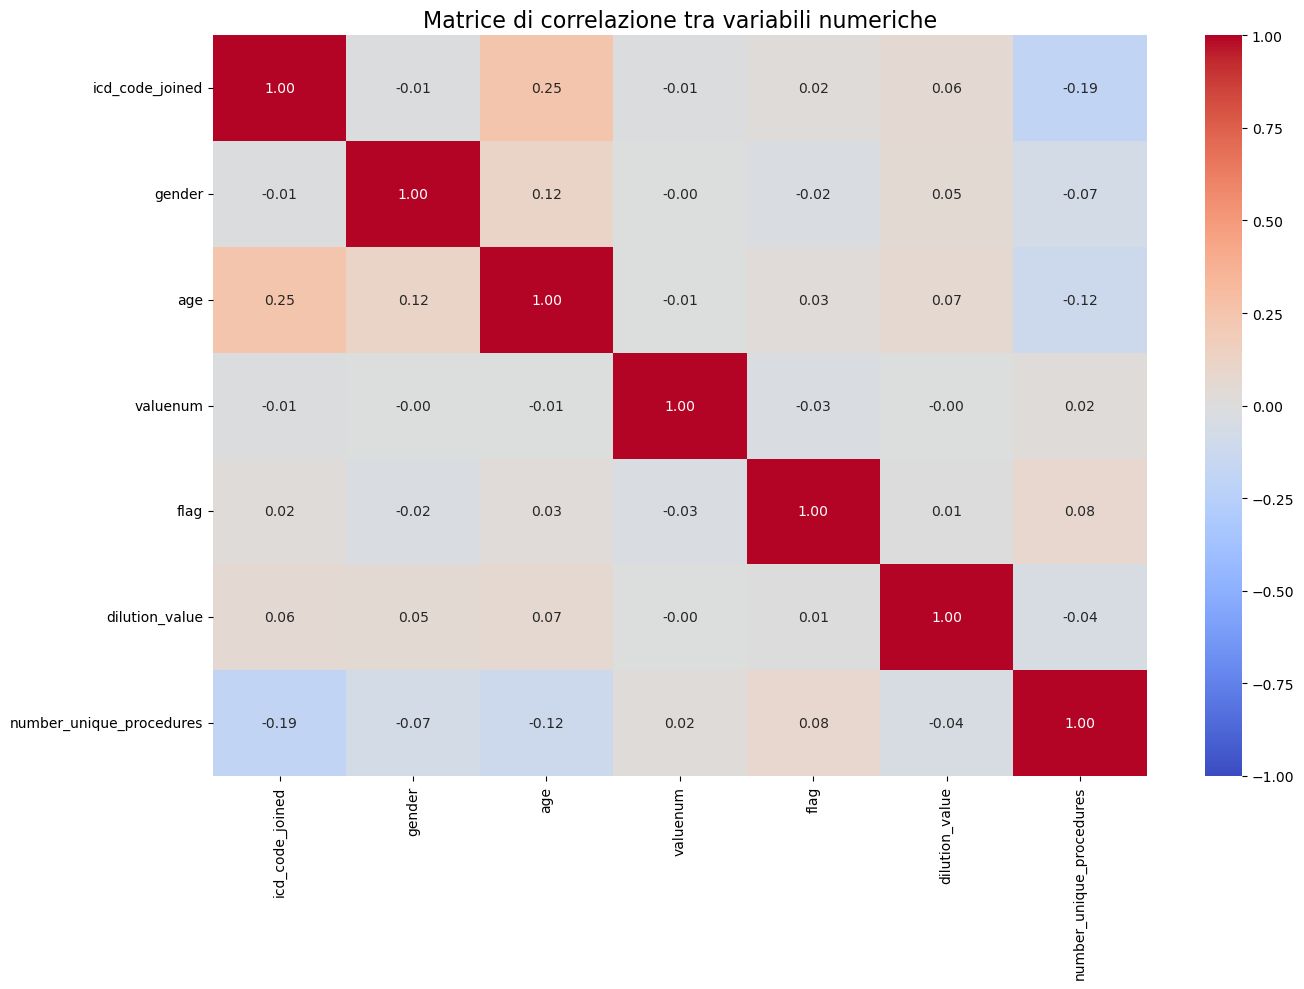

In [14]:
# Seleziona solo le colonne numeriche
df_num = joined_df[numeric_cols]

# Calcola la matrice di correlazione
corr_matrix = df_num.corr()

# Plot della heatmap
plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice di correlazione tra variabili numeriche", fontsize=16)
plt.tight_layout()
plt.show()


# Feature creation

In [15]:
# Creating the new features representing the profiles of the patients
#Taking the common attributes (subject_id,hadm_id, gender, age, ICD)
profile_cols = ['subject_id', 'hadm_id', 'gender', 'age', 'icd_code_joined']
profile_df = joined_df[profile_cols].drop_duplicates().reset_index(drop=True)

In [16]:
# Dropping duplicates based on the cols that makes a lab event unique
lab_uniq = joined_df.drop_duplicates(subset=['hadm_id','charttime_joined', 'label'])

#number of hammission
hadm_count=profile_df[['subject_id', 'hadm_id']].drop_duplicates().groupby('subject_id')['hadm_id'].size().reset_index(name='number_of_hadm')
# Dropping duplicates based on the cols that makes a lab event unique
profile_df = pd.merge(profile_df, hadm_count, on='subject_id', how='left')


# === LAB PROFILE FEATURES === #

#Creating the feature for the lab events, if "NO_LAB_LABEL" then count is 0
lab_event_counts = lab_uniq[lab_uniq['label'] != "NO_LAB_LABEL"].groupby(['subject_id', 'hadm_id'])['label'].count().reset_index()
lab_event_counts = lab_event_counts.rename(columns={'label': 'lab_event_count'})

# Merge con il profilo paziente
profile_df = pd.merge(profile_df, lab_event_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['lab_event_count'] = profile_df['lab_event_count'].fillna(0)
abnormal_lab_event_counts = lab_uniq[lab_uniq['flag'] == 1].groupby(['subject_id', 'hadm_id'])['flag'].count().reset_index()
abnormal_lab_event_counts = abnormal_lab_event_counts.rename(columns={'flag': 'abnormal_lab_event_count'})
profile_df = pd.merge(profile_df, abnormal_lab_event_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['abnormal_lab_event_count'] = profile_df['abnormal_lab_event_count'].fillna(0)
profile_df




,subject_id,hadm_id,gender,age,icd_code_joined,number_of_hadm,lab_event_count,abnormal_lab_event_count
0,10000980,29654838,1,75.0,50,2,45.0,18.0
1,10000980,26913865,1,75.0,21,2,124.0,51.0
2,10002013,24760295,1,69.0,21,1,40.0,15.0
3,10002155,23822395,1,69.0,21,1,276.0,106.0
4,10004457,28723315,0,66.0,35,1,21.0,6.0
...,...,...,...,...,...,...,...,...
4848,19998596,24860241,1,71.0,48,1,0.0,0.0
4849,19998597,23720781,1,57.0,31,1,0.0,0.0
4850,19998598,26940500,1,69.0,47,1,0.0,0.0
4851,19998599,20343031,0,59.0,30,1,0.0,0.0


In [17]:
# === MICROBIO PROFILE FEATURES === #

# Dropping duplicates based on the cols that makes a microbio event unique
microbio_uniq = joined_df.drop_duplicates(subset=['hadm_id','charttime_micro', 'spec_type_desc', 'org_name', 'ab_name'])

#Counting the number of microbio tests done per subject_id and hadm_id, if "NO_MICROBIO" then count is 0, using microbio_uniq
# Deduplicazione mirata sugli eventi microbiologici
microbio_test_counts = microbio_uniq[microbio_uniq['spec_type_desc'] != "NO_MICROBIO"].groupby(['subject_id', 'hadm_id'])['spec_type_desc'].nunique().reset_index()
microbio_test_counts = microbio_test_counts.rename(columns={'spec_type_desc': 'microbio_test_count'})

# Merge nel profilo paziente
profile_df = pd.merge(profile_df, microbio_test_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['microbio_test_count'] = profile_df['microbio_test_count'].fillna(0)

# Counting the number of unique microorganisms detected per subject_id and hadm_id, if "NO_ORG_DETECTED" then count is 0, useing microbio_uniq
microbio_counts = microbio_uniq[microbio_uniq['org_name'] != "NO_ORG_DETECTED"].groupby(['subject_id', 'hadm_id'])['org_name'].nunique().reset_index()
microbio_counts = microbio_counts.rename(columns={'org_name': 'unique_microorganisms_count'})
profile_df = pd.merge(profile_df, microbio_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['unique_microorganisms_count'] = profile_df['unique_microorganisms_count'].fillna(0)

resistant_microbio_counts = (
    microbio_uniq[(microbio_uniq["interpretation"] == "R") & (microbio_uniq["org_name"] != "NO_ORG_DETECTED")]
    .drop_duplicates(subset=["subject_id", "hadm_id", "org_name"])
    .groupby(["subject_id", "hadm_id"])["org_name"]
    .nunique()
    .reset_index(name="resistant_microorganisms_count")
)
profile_df = pd.merge(profile_df, resistant_microbio_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['resistant_microorganisms_count'] = profile_df['resistant_microorganisms_count'].fillna(0)

intermediate_microbio_counts = (
    microbio_uniq[(microbio_uniq["interpretation"] == "I") & (microbio_uniq["org_name"] != "NO_ORG_DETECTED")]
    .drop_duplicates(subset=["subject_id", "hadm_id", "org_name"])
    .groupby(["subject_id", "hadm_id"])["org_name"]
    .nunique()
    .reset_index(name="intermediate_microorganisms_count")
)
profile_df = pd.merge(profile_df, intermediate_microbio_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['intermediate_microorganisms_count'] = profile_df['intermediate_microorganisms_count'].fillna(0)

sensitive_microbio_counts = (
    microbio_uniq[(microbio_uniq["interpretation"] == "S") & (microbio_uniq["org_name"] != "NO_ORG_DETECTED")]
    .drop_duplicates(subset=["subject_id", "hadm_id", "org_name"])
    .groupby(["subject_id", "hadm_id"])["org_name"]
    .nunique()
    .reset_index(name="sensitive_microorganisms_count")
)
profile_df = pd.merge(profile_df, sensitive_microbio_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['sensitive_microorganisms_count'] = profile_df['sensitive_microorganisms_count'].fillna(0)
#numero di antibiotici diversi testati
ab_count=microbio_uniq[microbio_uniq['ab_name'] != "NO_AB_DETECTED"].groupby(['subject_id', 'hadm_id'])['ab_name'].nunique().reset_index()
ab_count = ab_count.rename(columns={'ab_name': 'unique_antibiotics_count'})
profile_df = pd.merge(profile_df, ab_count, on=['subject_id', 'hadm_id'], how='left')
profile_df['unique_antibiotics_count'] = profile_df['unique_antibiotics_count'].fillna(0)

# Creating the microbio test density using the charttime_microbio
microbio_event_times = microbio_uniq.groupby(['subject_id', 'hadm_id'])['charttime_micro'].agg(['min', 'max', 'count']).reset_index()
microbio_event_times['time_span_hours'] = (pd.to_datetime(microbio_event_times['max']) - pd.to_datetime(microbio_event_times['min'])).dt.total_seconds() / 3600
microbio_event_times['microbio_test_density'] = microbio_event_times.apply(
    lambda row: row['count'] / row['time_span_hours'] if row['time_span_hours'] > 0 else row['count'],
    axis=1
)
profile_df = pd.merge(profile_df, microbio_event_times[['subject_id', 'hadm_id', 'microbio_test_density']], on=['subject_id', 'hadm_id'], how='left')
profile_df['microbio_test_density'] = profile_df['microbio_test_density'].fillna(0)

profile_df

,subject_id,hadm_id,gender,age,icd_code_joined,number_of_hadm,lab_event_count,abnormal_lab_event_count,microbio_test_count,unique_microorganisms_count,resistant_microorganisms_count,intermediate_microorganisms_count,sensitive_microorganisms_count,unique_antibiotics_count,microbio_test_density
0,10000980,29654838,1,75.0,50,2,45.0,18.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
1,10000980,26913865,1,75.0,21,2,124.0,51.0,1.0,0.0,0.0,0.0,0.0,0.0,1.000000
2,10002013,24760295,1,69.0,21,1,40.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
3,10002155,23822395,1,69.0,21,1,276.0,106.0,4.0,0.0,0.0,0.0,0.0,0.0,0.032412
4,10004457,28723315,0,66.0,35,1,21.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4848,19998596,24860241,1,71.0,48,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
4849,19998597,23720781,1,57.0,31,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
4850,19998598,26940500,1,69.0,47,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
4851,19998599,20343031,0,59.0,30,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000


In [18]:
# === PROCEDURE PROFILE FEATURES === #
# Dropping duplicates based on the cols that makes a procedure event unique
procedure_uniq = joined_df.drop_duplicates(subset=['subject_id', 'hadm_id','icd_code_proc'])

# Count the number of unique procedures (splitting comma-separated codes) per subject_id and hadm_id
# If "NO_PROCEDURES" then count is 0
procedure_counts = (
    procedure_uniq[procedure_uniq['icd_code_proc'] != "NO_PROCEDURES"]
    .groupby(['subject_id', 'hadm_id'])['icd_code_proc']
    .apply(lambda x: sum(len(proc.split(',')) for proc in x))
    .reset_index(name='unique_procedures_count')
)

# Merge with profile_df
profile_df = pd.merge(profile_df, procedure_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['unique_procedures_count'] = profile_df['unique_procedures_count'].fillna(0)
profile_df

# == SOME INDICATORS ==
# Calcolo del massimo valore di glucosio per ogni paziente e ammissione
glucose_max = (
    lab_uniq[lab_uniq['label'] == "Glucose"]  # seleziona solo gli eventi di glucosio
    .groupby(['subject_id', 'hadm_id'])['valuenum']  # 'value' è la colonna con i risultati numerici
    .max()
    .reset_index(name='max_glucose')
)

# Merge con il profilo paziente
profile_df = pd.merge(profile_df, glucose_max, on=['subject_id', 'hadm_id'], how='left')
profile_df['max_glucose'] = profile_df['max_glucose'].fillna(0)

#


# Removes all the counts columns used for calculations
#cols = profile_df.columns
#counts_cols = [col for col in cols if 'count' in col and col not in ['subject_id', 'hadm_id']]
#profile_df = profile_df.drop(columns=counts_cols)

# Remove duplicates (just in case)
profile_df = profile_df.drop_duplicates().reset_index(drop=True)
profile_df


,subject_id,hadm_id,gender,age,icd_code_joined,number_of_hadm,lab_event_count,abnormal_lab_event_count,microbio_test_count,unique_microorganisms_count,resistant_microorganisms_count,intermediate_microorganisms_count,sensitive_microorganisms_count,unique_antibiotics_count,microbio_test_density,unique_procedures_count,max_glucose
0,10000980,29654838,1,75.0,50,2,45.0,18.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,138.0
1,10000980,26913865,1,75.0,21,2,124.0,51.0,1.0,0.0,0.0,0.0,0.0,0.0,1.000000,7.0,163.0
2,10002013,24760295,1,69.0,21,1,40.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,2.0,200.0
3,10002155,23822395,1,69.0,21,1,276.0,106.0,4.0,0.0,0.0,0.0,0.0,0.0,0.032412,8.0,140.0
4,10004457,28723315,0,66.0,35,1,21.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,92.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4848,19998596,24860241,1,71.0,48,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
4849,19998597,23720781,1,57.0,31,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
4850,19998598,26940500,1,69.0,47,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
4851,19998599,20343031,0,59.0,30,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0


In [19]:
#binary vector for the icd_code
# === ICD MULTI-HOT VECTOR (0/1) per paziente === #

# Assumo: heart_diagnoses_df è il df delle diagnosi
#         profile_df contiene subject_id e hadm_id

# 1. Elenco di tutti gli ICD distinti (ordinati per stabilità)
unique_icd = (
    joined_df['icd_code_joined']
    .dropna()
    .drop_duplicates()
    .sort_values()
    .tolist()
)

print("Numero ICD distinti:", len(unique_icd))
print("ICD:", unique_icd)

# 2. Matrice ICD multi-hot per admisstion (subject_id + hadm_id)
icd_matrix = (
    joined_df[['subject_id', 'hadm_id', 'icd_code_joined']]
    .dropna(subset=['icd_code_joined'])
    .assign(flag=1)
    .pivot_table(
        index=['subject_id', 'hadm_id'],
        columns='icd_code_joined',
        values='flag',
        fill_value=0
    )
    .reset_index()
)

# 3. Merge con profile_df (a livello admission)
profile_df = profile_df.merge(icd_matrix, on=['subject_id','hadm_id'], how='left')

# Riempio eventuali ICD mancanti (paziente senza quel codice)
for col in unique_icd:
    profile_df[col] = profile_df[col].fillna(0).astype(int)

# DOPO questo farai il raggruppamento per paziente:
# patient_df = profile_df.groupby('subject_id').agg({
#     ... tue aggregazioni ...
#     aggiungi gli ICD con metodo 'max'
# })

# Esempio di aggregazione ICD:
# for col in unique_icd:
#     agg_dict[col] = 'max'


Numero ICD distinti: 20
ICD: [20, 21, 22, 24, 25, 30, 31, 33, 34, 35, 36, 40, 42, 44, 45, 46, 47, 48, 49, 50]


In [20]:
# Ottieni tutte le colonne della matrice ICD
profile_df.columns = profile_df.columns.astype(str)
icd_columns = [col for col in profile_df.columns if col.startswith('icd_code')]

# Crea un dizionario di aggregazione per gli ICD code
agg_dict = {col: 'max' for col in icd_columns}

# Aggiungi le altre aggregazioni
agg_dict.update({
    'number_of_hadm': 'first',
    'gender': 'first',
    'age': 'first',
    'lab_event_count': 'sum',
    'abnormal_lab_event_count': 'sum',
    'microbio_test_count': 'sum',
    'unique_microorganisms_count': 'sum',
    'resistant_microorganisms_count': 'sum',
    'intermediate_microorganisms_count': 'sum',
    'sensitive_microorganisms_count': 'sum',
    'unique_antibiotics_count': 'sum',
    'unique_procedures_count': 'sum',
    'max_glucose': 'max'
})

# Raggruppa per 'subject_id' usando il dizionario di aggregazione
profile_df = profile_df.groupby('subject_id').agg(agg_dict).reset_index()
profile_df.drop_duplicates(inplace=True)


In [21]:
#ratio post aggregation per hadm
# Creating the ratio of abnormal lab events to total lab events, if no lab events then ratio is 0, using lab_uniq
profile_df['abnormal_lab_event_ratio'] = profile_df.apply(
    lambda row: row['abnormal_lab_event_count'] / row['lab_event_count'] if row['lab_event_count'] > 0 else 0,
    axis=1
)
profile_df=profile_df.drop(columns=['abnormal_lab_event_ratio'])
# Ratio of resistant microorganisms to total microorganisms detected, if intepretation is "NO_INTERPRETATION" then count is 0, using microbio_uniq

profile_df['resistant_microorganism_ratio'] = (
    profile_df['resistant_microorganisms_count'] / profile_df['unique_microorganisms_count']
).fillna(0)  # Sostituisce NaN con 0

# Ratio of intermediate microorganisms to total microorganisms detected, if intepretation is "NO_INTERPRETATION" then count is 0, using microbio_uniq

profile_df['intermediate_microorganism_ratio'] = profile_df.apply(
    lambda row: row['intermediate_microorganisms_count'] / row['unique_microorganisms_count'] if row['unique_microorganisms_count'] > 0 else 0,
    axis=1
)

# Ratio of sensitive microorganisms to total microorganisms detected, if intepretation is "NO_INTERPRETATION" then count is 0, using microbio_uniq

profile_df['sensitive_microorganism_ratio'] = profile_df.apply(
    lambda row: row['sensitive_microorganisms_count'] / row['unique_microorganisms_count'] if row['unique_microorganisms_count'] > 0 else 0,
    axis=1
)
profile_df = profile_df.drop(columns=['resistant_microorganisms_count'])  # Corretto
profile_df = profile_df.drop(columns=['intermediate_microorganisms_count'])  # Corretto
profile_df = profile_df.drop(columns=['sensitive_microorganisms_count'])  # Corretto


   

profile_df.to_csv("../../data/profiles/patient_profile.csv", index=False)
profile_df

,subject_id,icd_code_joined,number_of_hadm,gender,age,lab_event_count,abnormal_lab_event_count,microbio_test_count,unique_microorganisms_count,unique_antibiotics_count,unique_procedures_count,max_glucose,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio
0,10000980,50,2,1,75.0,169.0,69.0,1.0,0.0,0.0,7.0,163.0,0.0,0.0,0.0
1,10002013,21,1,1,69.0,40.0,15.0,0.0,0.0,0.0,2.0,200.0,0.0,0.0,0.0
2,10002155,21,1,1,69.0,276.0,106.0,4.0,0.0,0.0,8.0,140.0,0.0,0.0,0.0
3,10004457,35,1,0,66.0,21.0,6.0,0.0,0.0,0.0,0.0,92.0,0.0,0.0,0.0
4,10007058,21,1,0,48.0,112.0,42.0,2.0,0.0,0.0,2.0,111.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,48,1,1,71.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4379,19998597,31,1,1,57.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4380,19998598,47,1,1,69.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4381,19998599,30,1,0,59.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Visual exploration of the new features


In [22]:
profile_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4383 entries, 0 to 4382
Data columns (total 15 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   subject_id                        4383 non-null   int64  
 1   icd_code_joined                   4383 non-null   int64  
 2   number_of_hadm                    4383 non-null   int64  
 3   gender                            4383 non-null   int64  
 4   age                               4383 non-null   float64
 5   lab_event_count                   4383 non-null   float64
 6   abnormal_lab_event_count          4383 non-null   float64
 7   microbio_test_count               4383 non-null   float64
 8   unique_microorganisms_count       4383 non-null   float64
 9   unique_antibiotics_count          4383 non-null   float64
 10  unique_procedures_count           4383 non-null   float64
 11  max_glucose                       4383 non-null   float64
 12  resist

In [23]:
# Conversione in stringa (più comune)
profile_df['subject_id'] = profile_df['subject_id'].astype(object)
#profile_df['hadm_id'] = profile_df['hadm_id'].astype(object)
#profile_df['glucose_trend']=profile_df['glucose_trend'].astype(float)

In [24]:
profile_df.describe()

,icd_code_joined,number_of_hadm,gender,age,lab_event_count,abnormal_lab_event_count,microbio_test_count,unique_microorganisms_count,unique_antibiotics_count,unique_procedures_count,max_glucose,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio
count,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000
mean,35.410449,1.107232,0.360027,70.107004,135.996806,59.051563,1.209446,0.201232,0.957563,3.200548,143.081679,0.042254,0.015772,0.076001
std,12.757906,0.374812,0.480063,9.441022,141.890953,79.868831,1.627842,0.595225,3.214885,3.232322,47.633985,0.190381,0.115299,0.256235
min,20.000000,1.000000,0.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,21.000000,1.000000,0.000000,66.000000,54.000000,15.000000,0.000000,0.000000,0.000000,0.000000,110.000000,0.000000,0.000000,0.000000
50%,34.000000,1.000000,0.000000,69.000000,93.000000,33.000000,1.000000,0.000000,0.000000,2.000000,140.000000,0.000000,0.000000,0.000000
75%,50.000000,1.000000,1.000000,75.000000,171.000000,71.000000,2.000000,0.000000,0.000000,5.000000,191.000000,0.000000,0.000000,0.000000
max,50.000000,5.000000,1.000000,95.000000,2221.000000,1200.000000,15.000000,9.000000,28.000000,23.000000,210.000000,1.000000,1.000000,1.000000


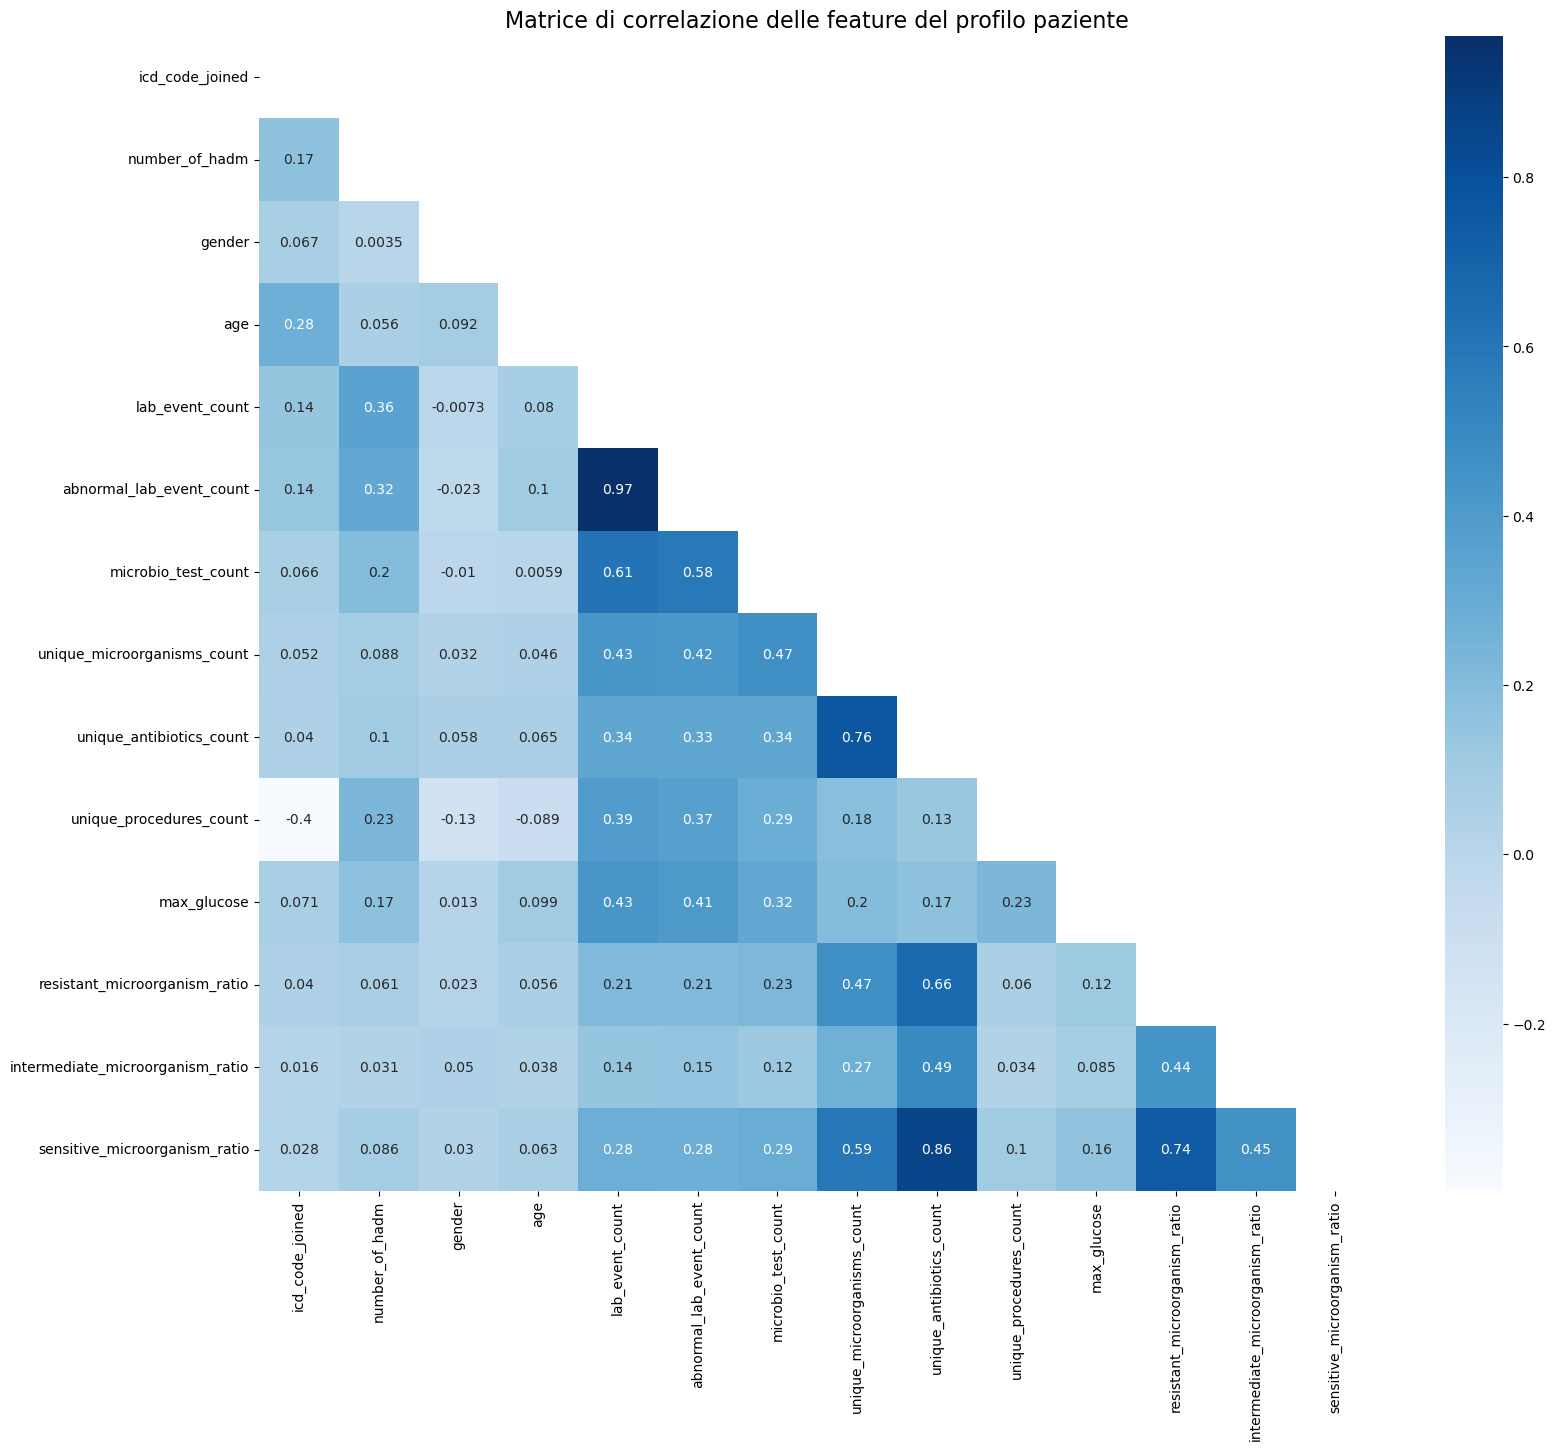

In [25]:
#correletion
# Seleziona solo le colonne numeriche dal profilo paziente
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

# Calcola la matrice di correlazione
corr_matrix = profile_num.corr()

# Maschera triangolare superiore
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Plot
plt.figure(figsize=(18,15))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', mask=mask)
plt.title("Matrice di correlazione delle feature del profilo paziente", fontsize=16)
plt.show()

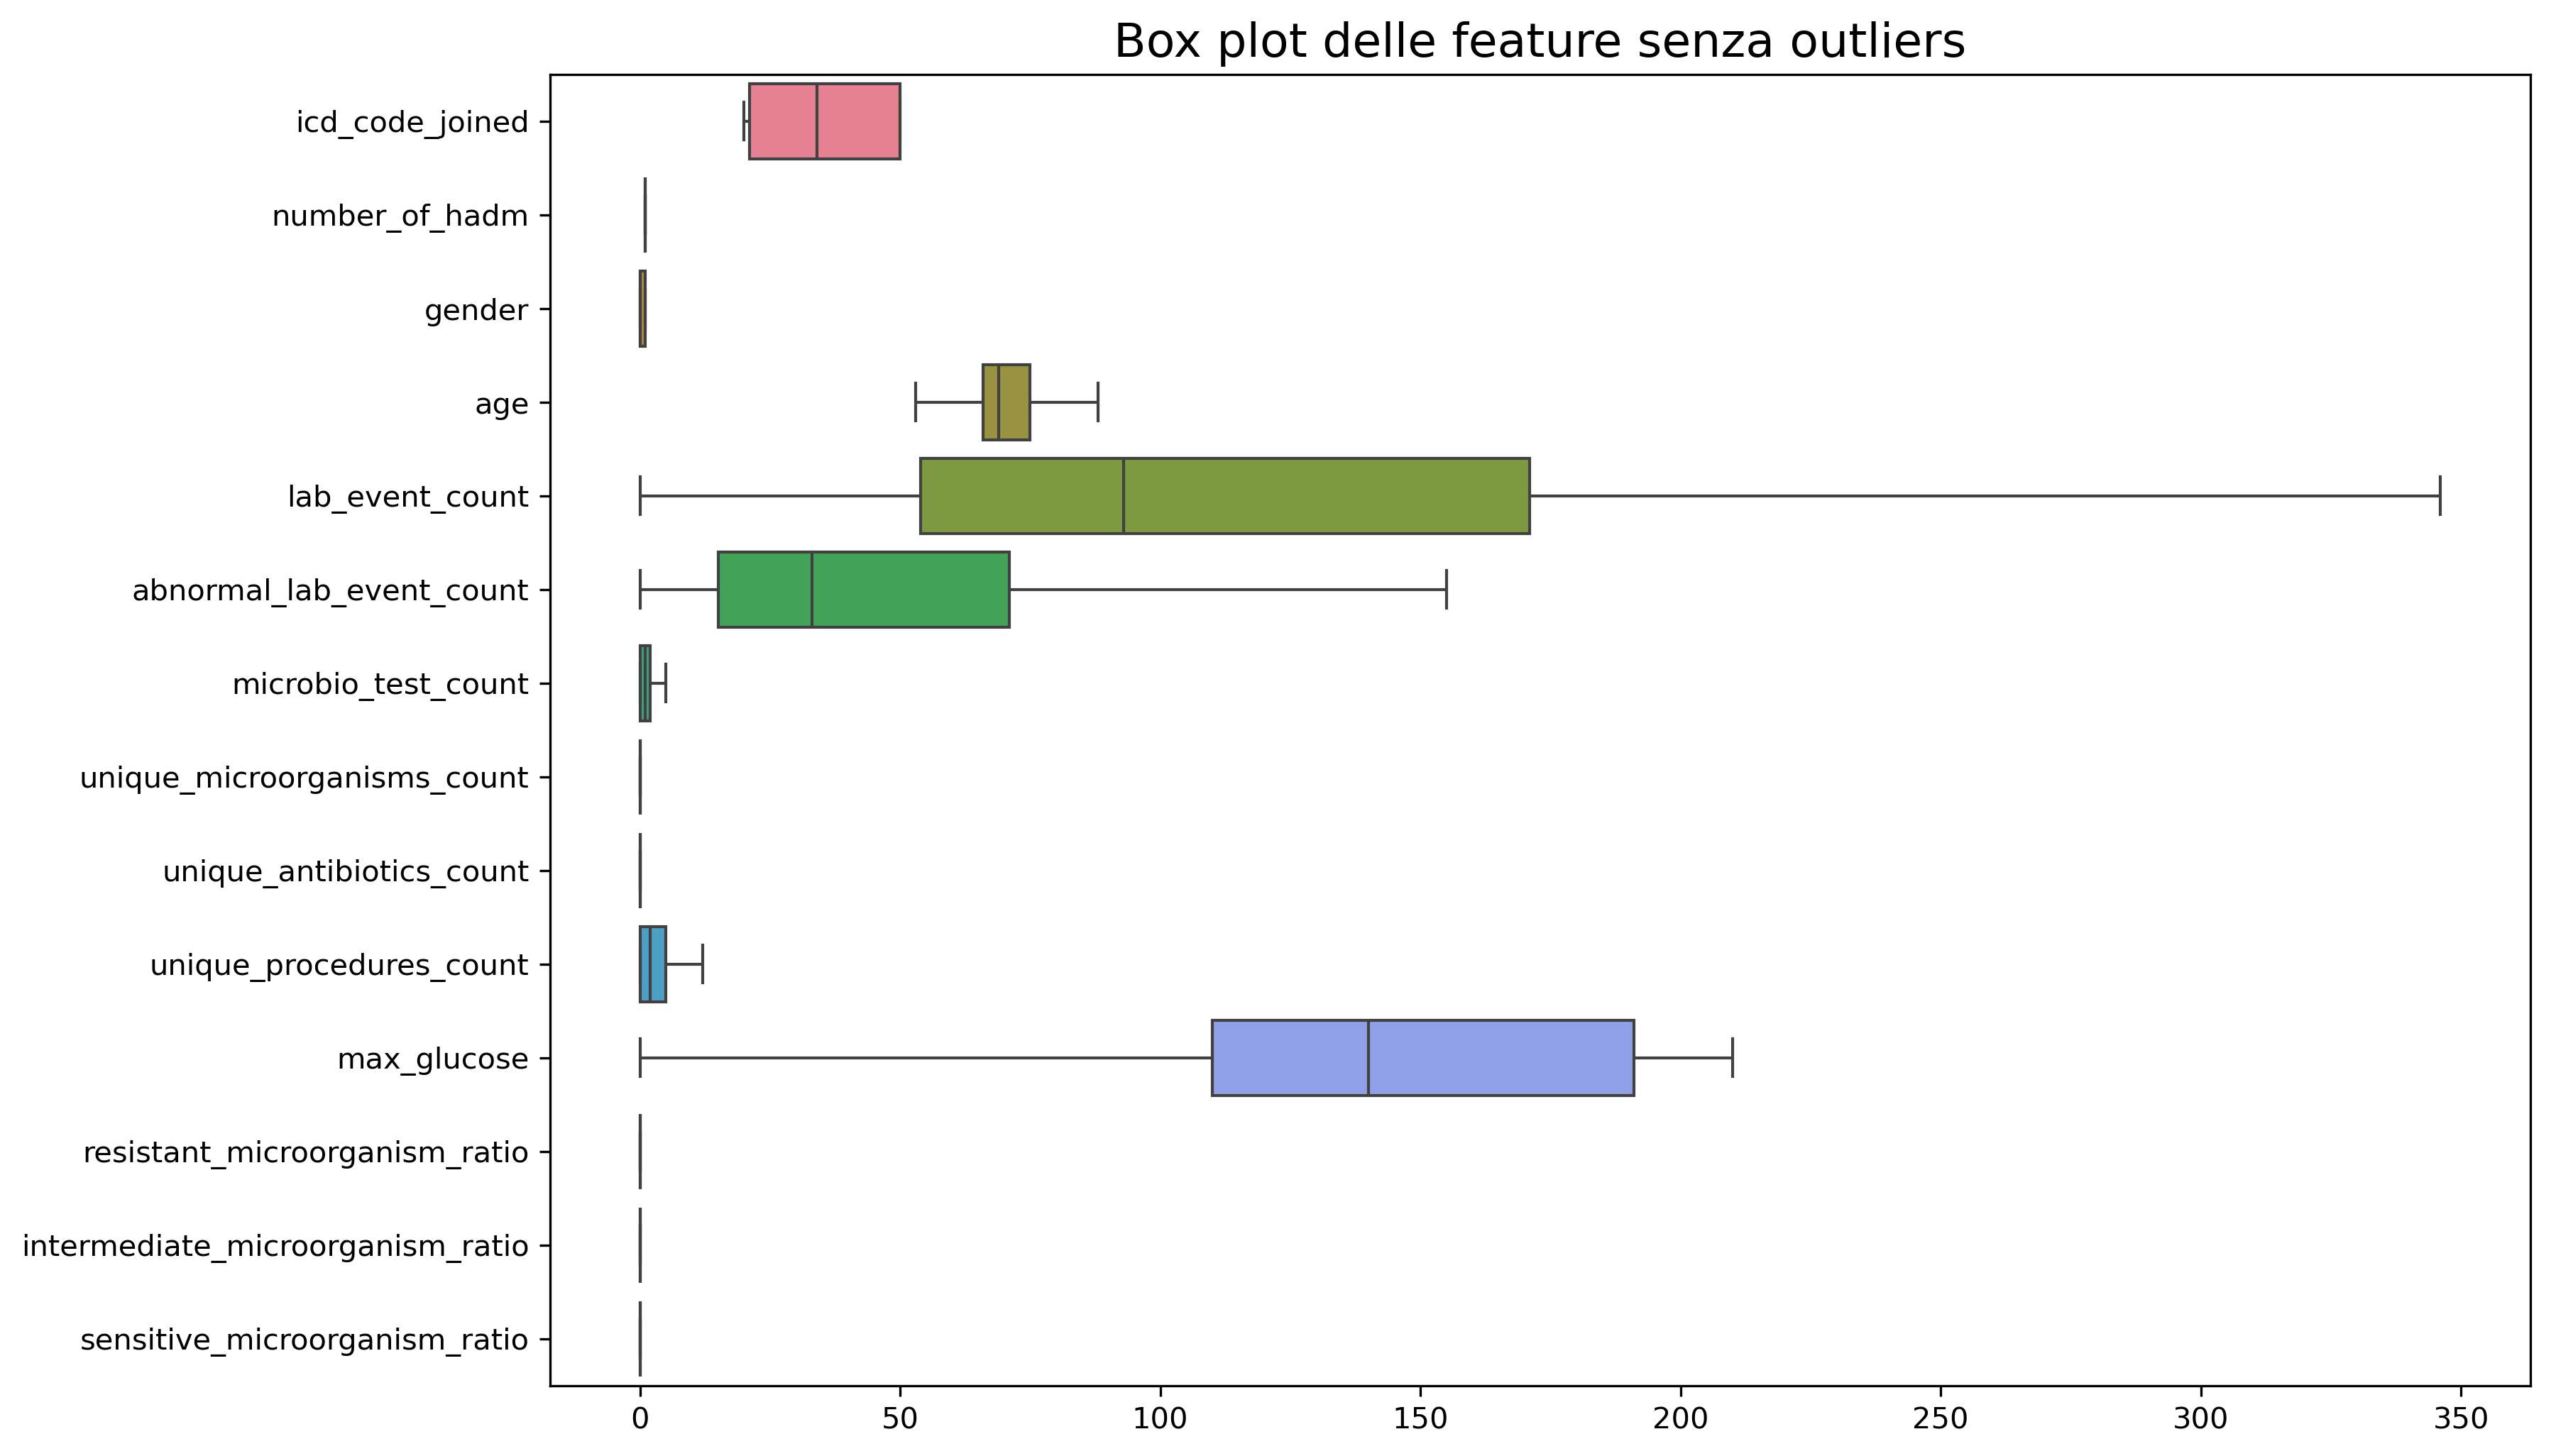

In [26]:
plt.figure(figsize=(12,8), dpi=300)
sns.boxplot(data=profile_num, orient="h", showfliers=False)
plt.title("Box plot delle feature senza outliers", fontsize=16)
plt.show()

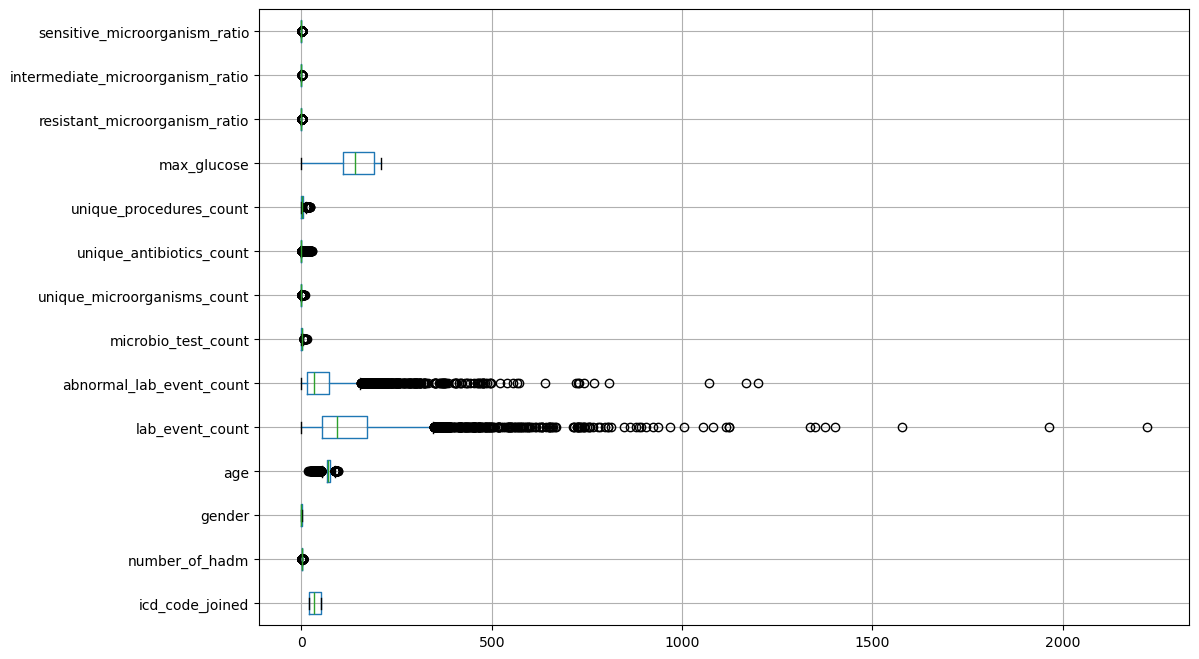

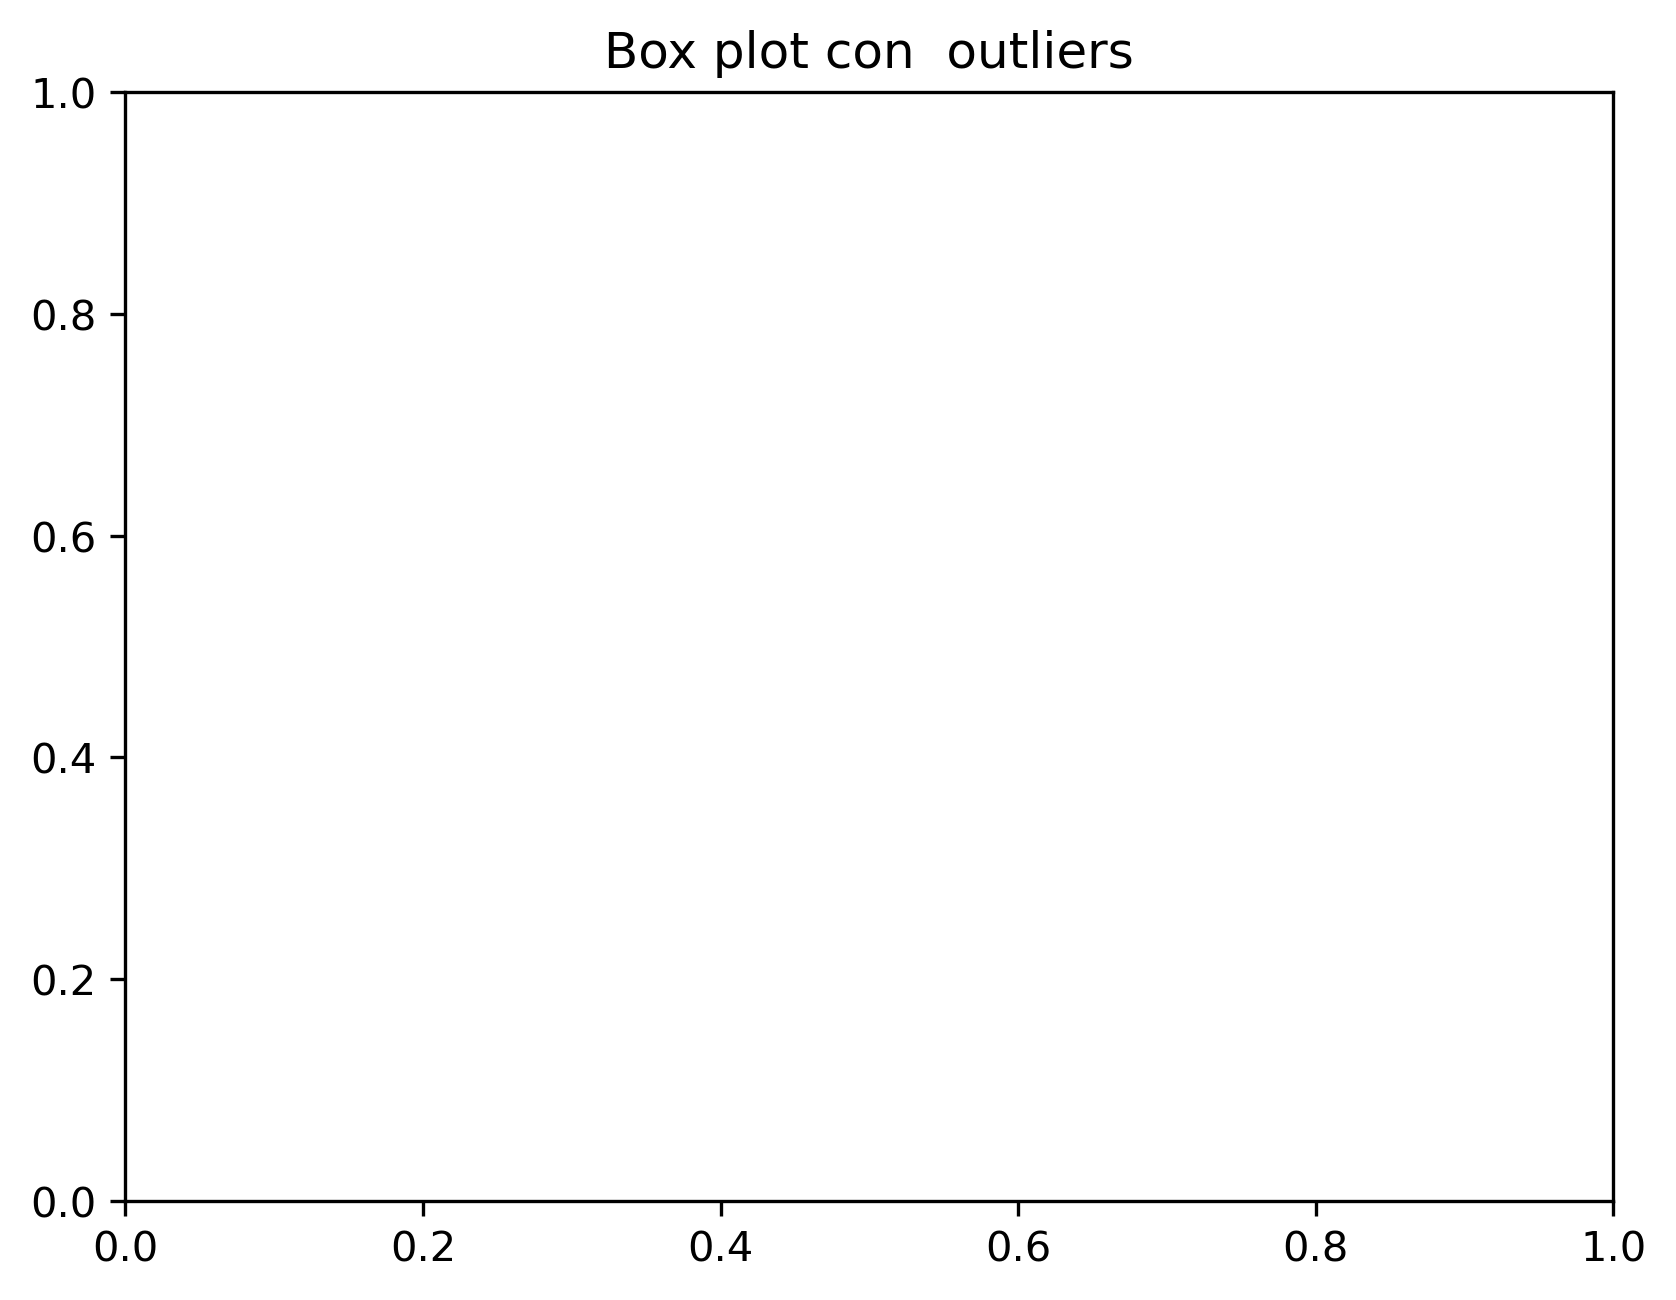

In [27]:
profile_num.boxplot(vert=False, figsize=(12, 8), showfliers=True)
plt.figure(dpi=300)
plt.title('Box plot con  outliers')
plt.show()

## Visual exploration
The following plots give a quick overview of age distribution in the cohort, the tests with the highest abnormal rates, and how resistance relates to antibiotic coverage.

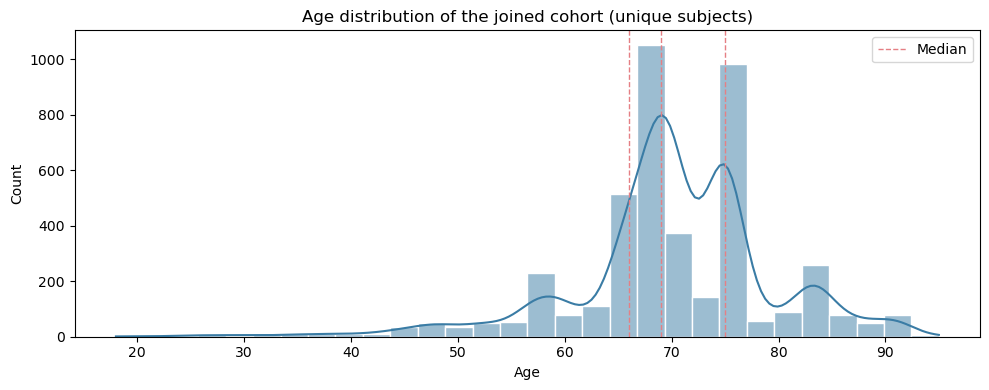

In [28]:
# Age distribution with KDE overlay and highlighted quartiles (unique subjects)
unique_subject_age = (
    joined_df[['subject_id', 'age']]
    .dropna(subset=['age'])
    .drop_duplicates(subset='subject_id')
)

plt.figure(figsize=(10, 4))
sns.histplot(
    data=unique_subject_age,
    x='age',
    bins=30,
    kde=True,
    color='#3A7CA5',
    edgecolor='white'
)
q1, q2, q3 = unique_subject_age['age'].quantile([0.25, 0.5, 0.75])
for q, label in zip([q1, q2, q3], ['Q1', 'Median', 'Q3']):
    plt.axvline(q, color='#E57F84', linestyle='--', linewidth=1, label=label if label == 'Median' else None)
plt.title('Age distribution of the joined cohort (unique subjects)')
plt.xlabel('Age')
plt.ylabel('Count')
plt.legend(loc='upper right')
plt.tight_layout()

## Sex distribution per ICD code

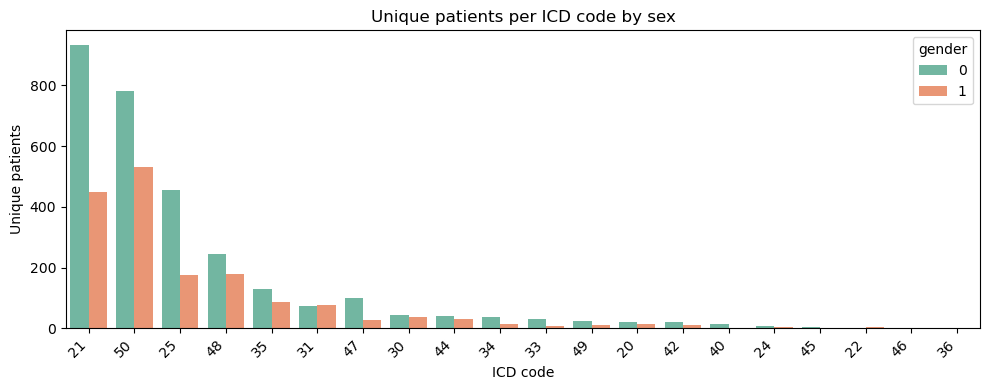

In [29]:
counts = (
    joined_df.groupby(['icd_code_joined', 'gender'])['subject_id']
    .nunique()
    .reset_index(name='unique_patients')
)

icd_order = (
    counts.groupby('icd_code_joined')['unique_patients']
    .sum()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(10, 4))
sns.barplot(
    data=counts,
    x='icd_code_joined',
    y='unique_patients',
    hue='gender',
    palette='Set2',
    order=icd_order
)
plt.title('Unique patients per ICD code by sex')
plt.xlabel('ICD code')
plt.ylabel('Unique patients')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

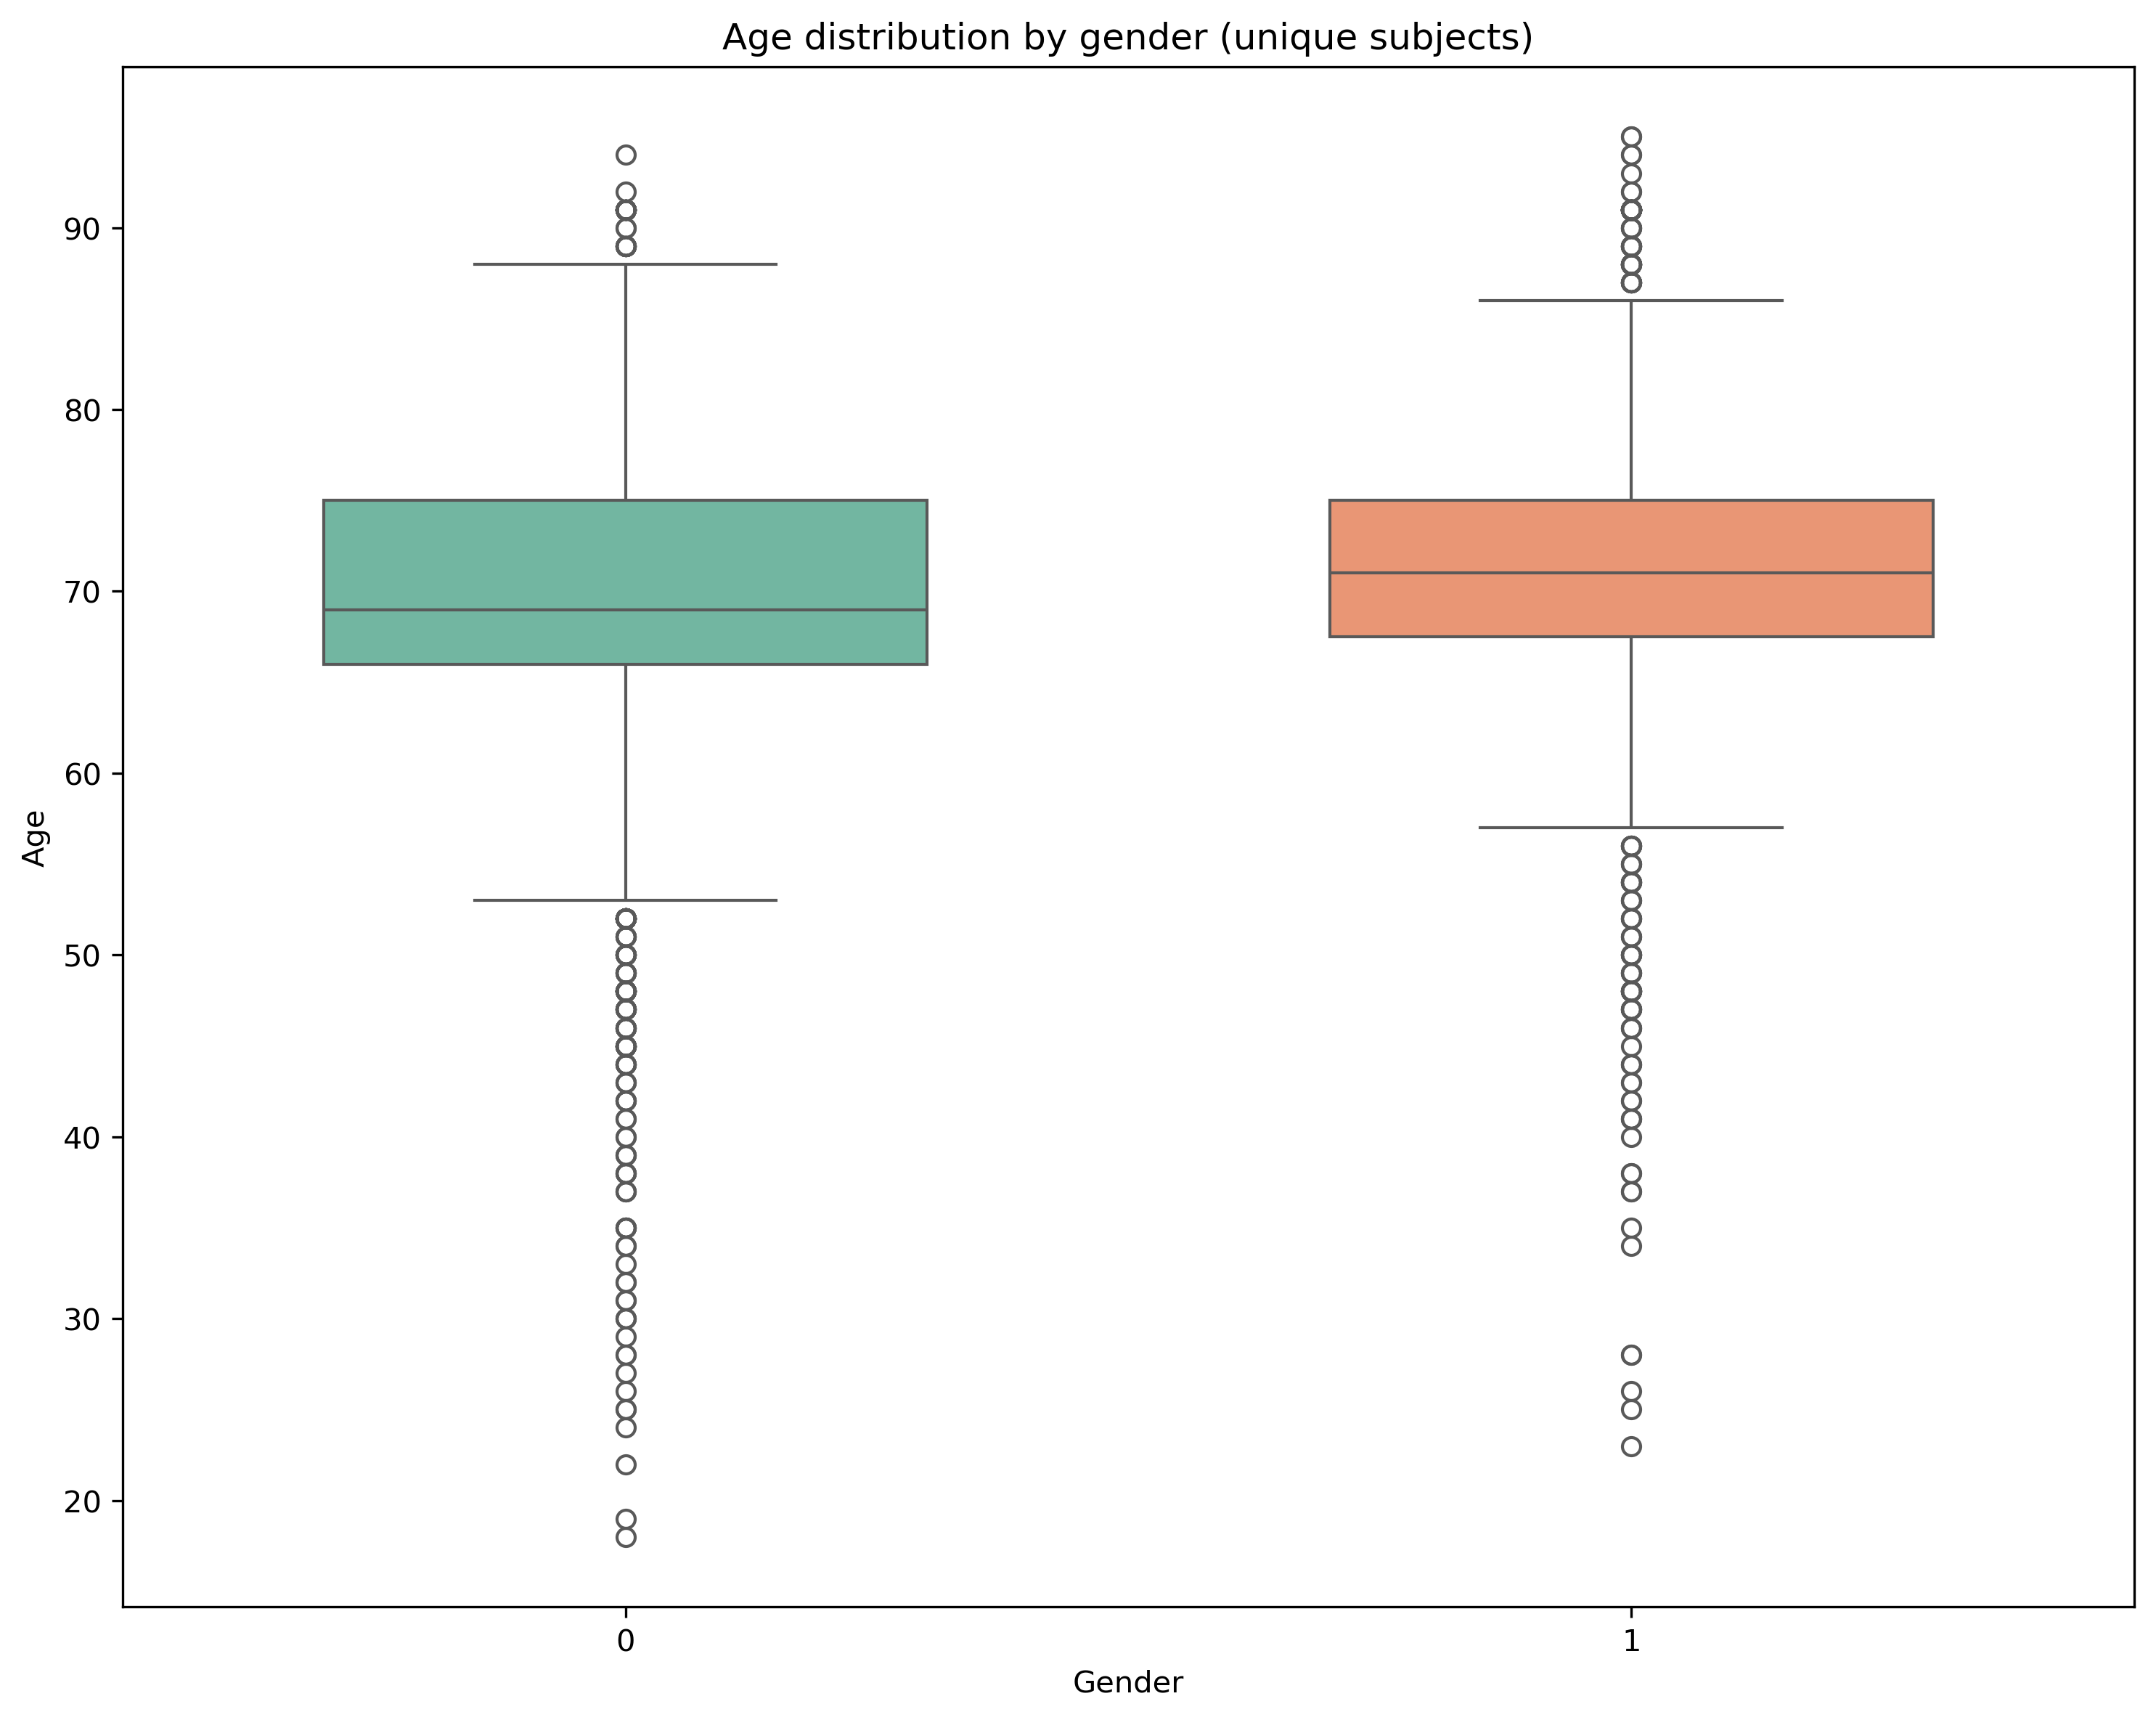

In [30]:
subject_age = (
    joined_df[['subject_id', 'gender', 'age']]
    .dropna(subset=['gender', 'age'])
    .drop_duplicates(subset='subject_id')
)

plt.figure(figsize=(10, 8), dpi=300)
sns.boxplot(
    data=subject_age,
    x='gender',
    y='age',
    hue='gender',
    palette='Set2',
    width=0.6,
    dodge=False,
    legend=False
)
plt.title('Age distribution by gender (unique subjects)')
plt.xlabel('Gender')
plt.ylabel('Age')
plt.tight_layout()

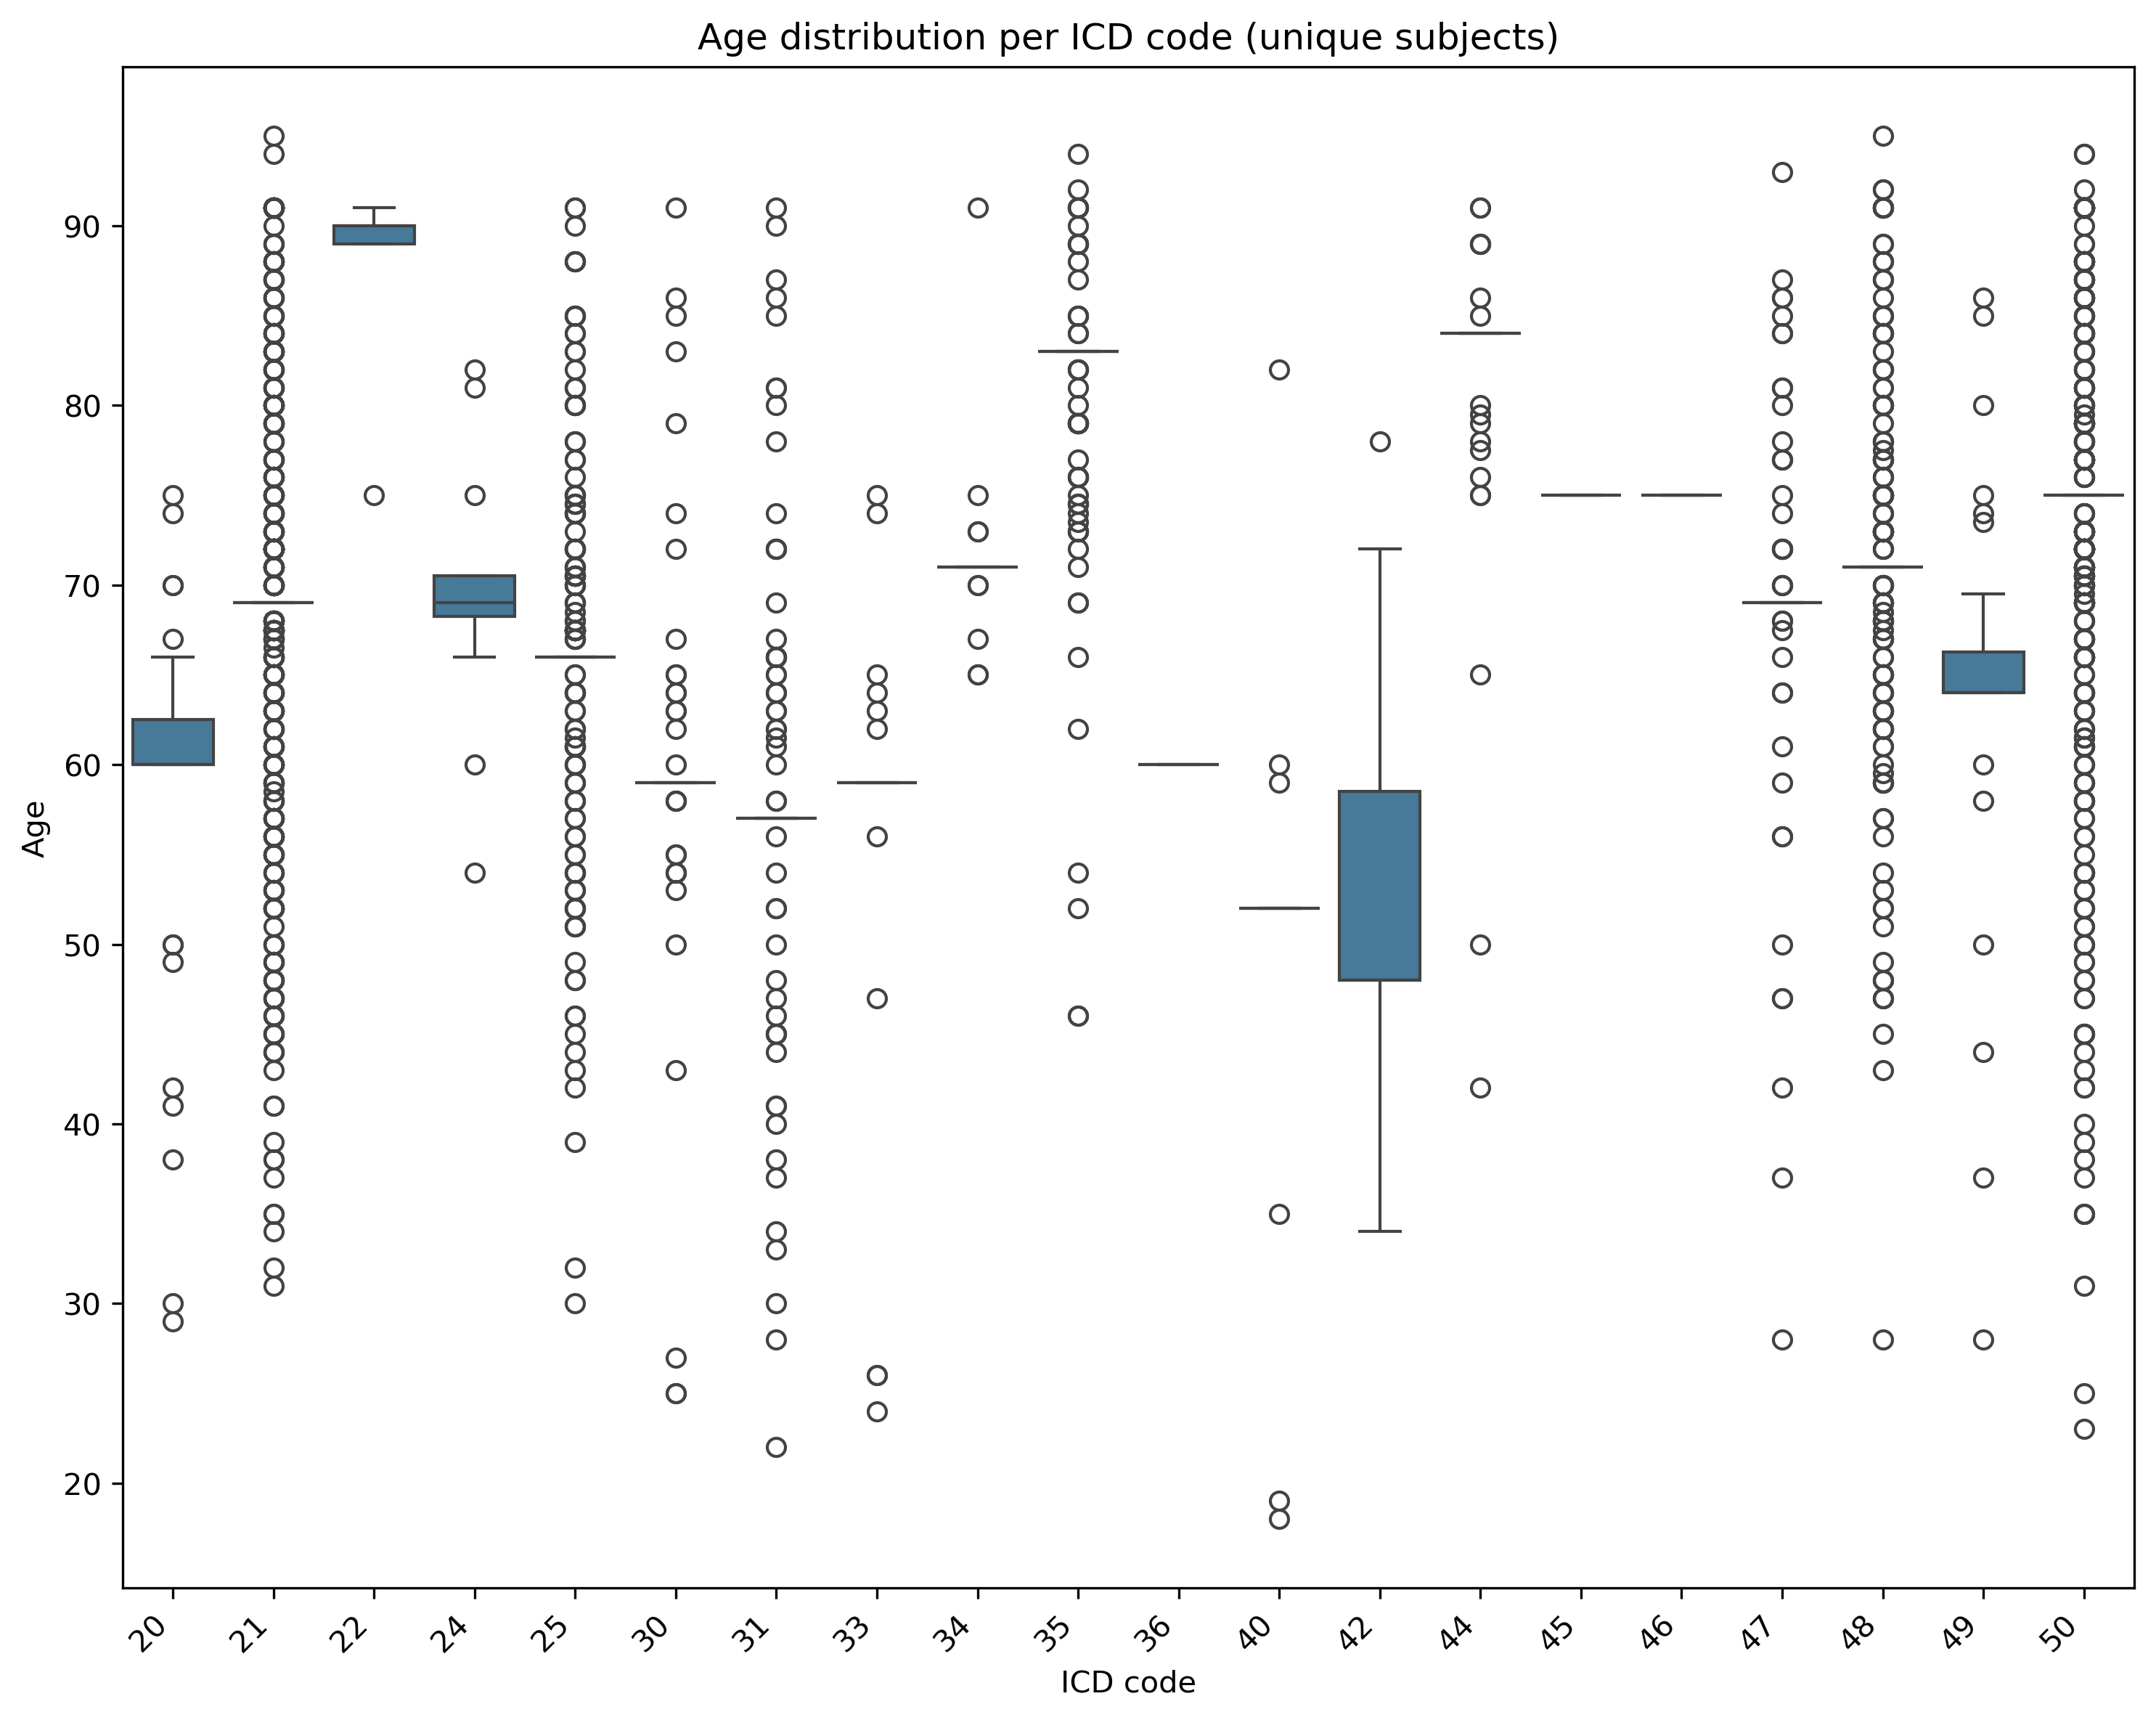

In [31]:
#to visualize for each icd_code the age of the patient 
icd_age = (
    joined_df[['subject_id', 'icd_code_joined', 'age']]
    .dropna(subset=['icd_code_joined', 'age'])
    .drop_duplicates(subset=['subject_id', 'icd_code_joined'])
)

plt.figure(figsize=(10, 8), dpi=300)
sns.boxplot(
    data=icd_age,
    x='icd_code_joined',
    y='age',
    color='#3A7CA5'
)
plt.title('Age distribution per ICD code (unique subjects)')
plt.xlabel('ICD code')
plt.ylabel('Age')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

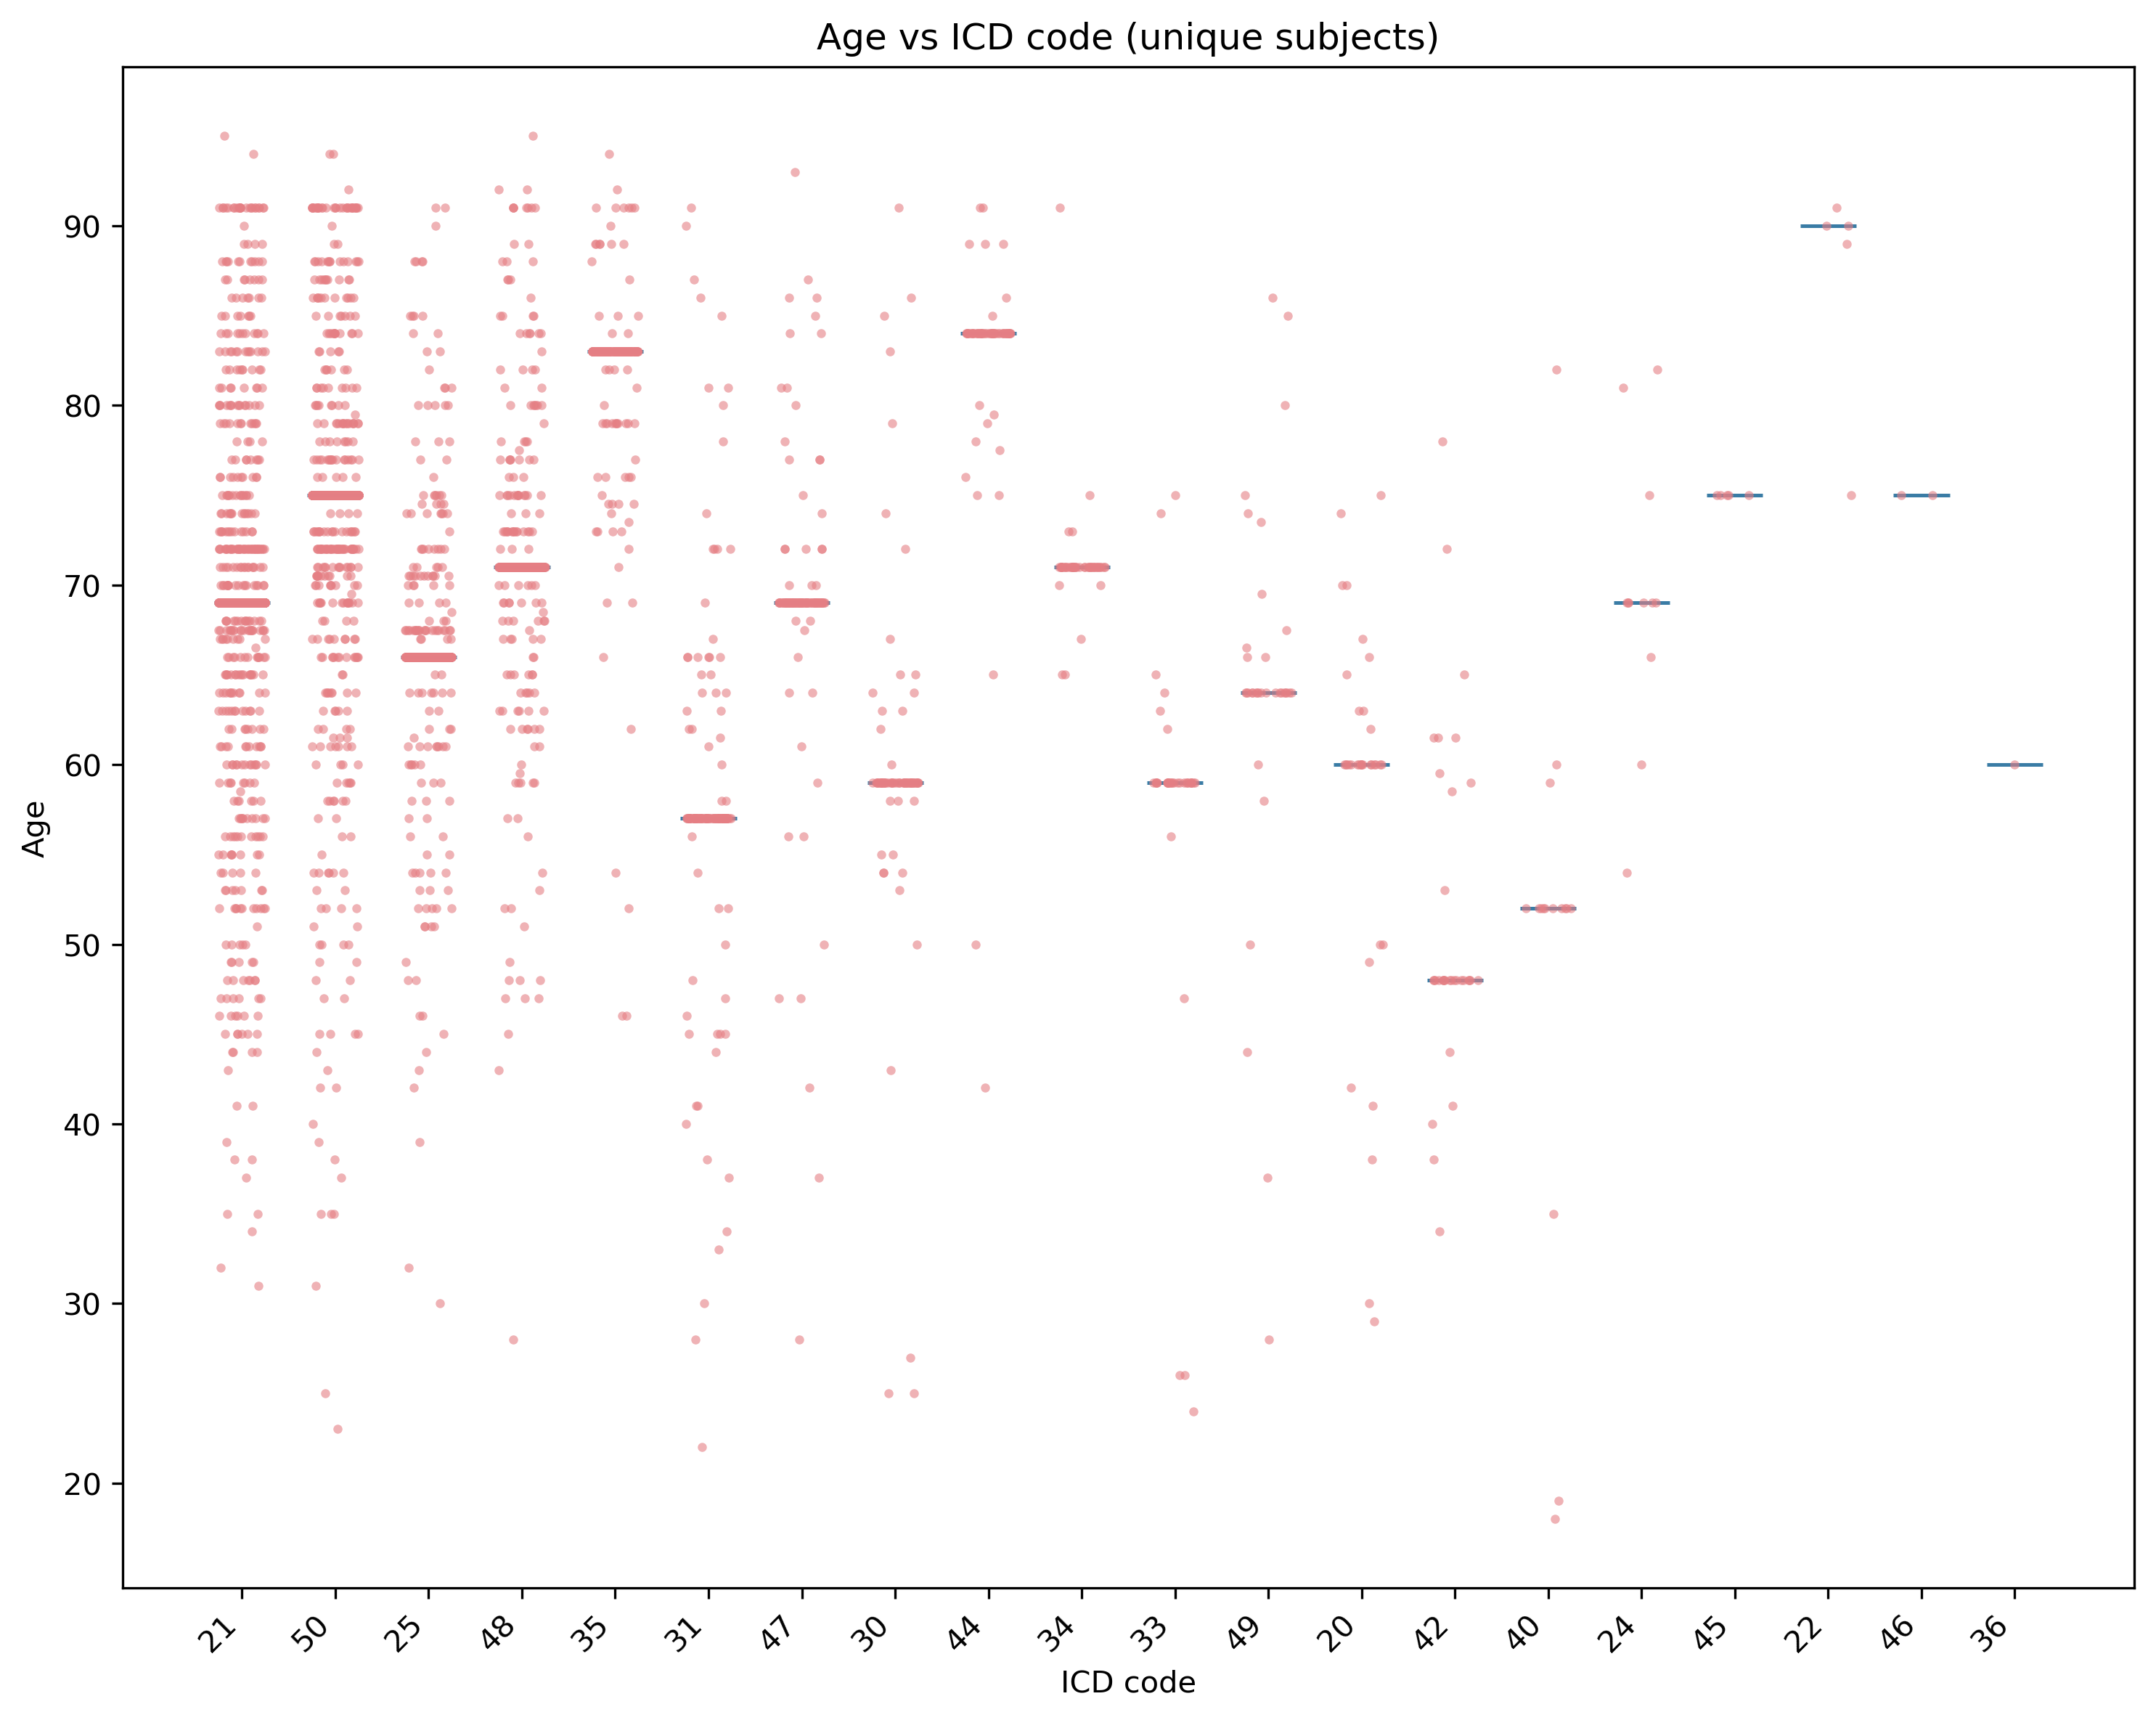

In [32]:
icd_order = (
    icd_age.groupby('icd_code_joined')['subject_id']
    .nunique()
    .sort_values(ascending=False)
    .index
)

median_age_by_icd = (
    icd_age.groupby('icd_code_joined')['age']
    .median()
    .reindex(icd_order)
)

plt.figure(figsize=(10, 8), dpi=300)
sns.stripplot(
    data=icd_age,
    x='icd_code_joined',
    y='age',
    order=icd_order,
    color='#E57F84',
    jitter=0.25,
    size=3,
    alpha=0.6
)

for idx, age in enumerate(median_age_by_icd):
    plt.hlines(age, idx - 0.3, idx + 0.3, color='#3A7CA5', linewidth=1.2)

plt.title('Age vs ICD code (unique subjects)')
plt.xlabel('ICD code')
plt.ylabel('Age')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

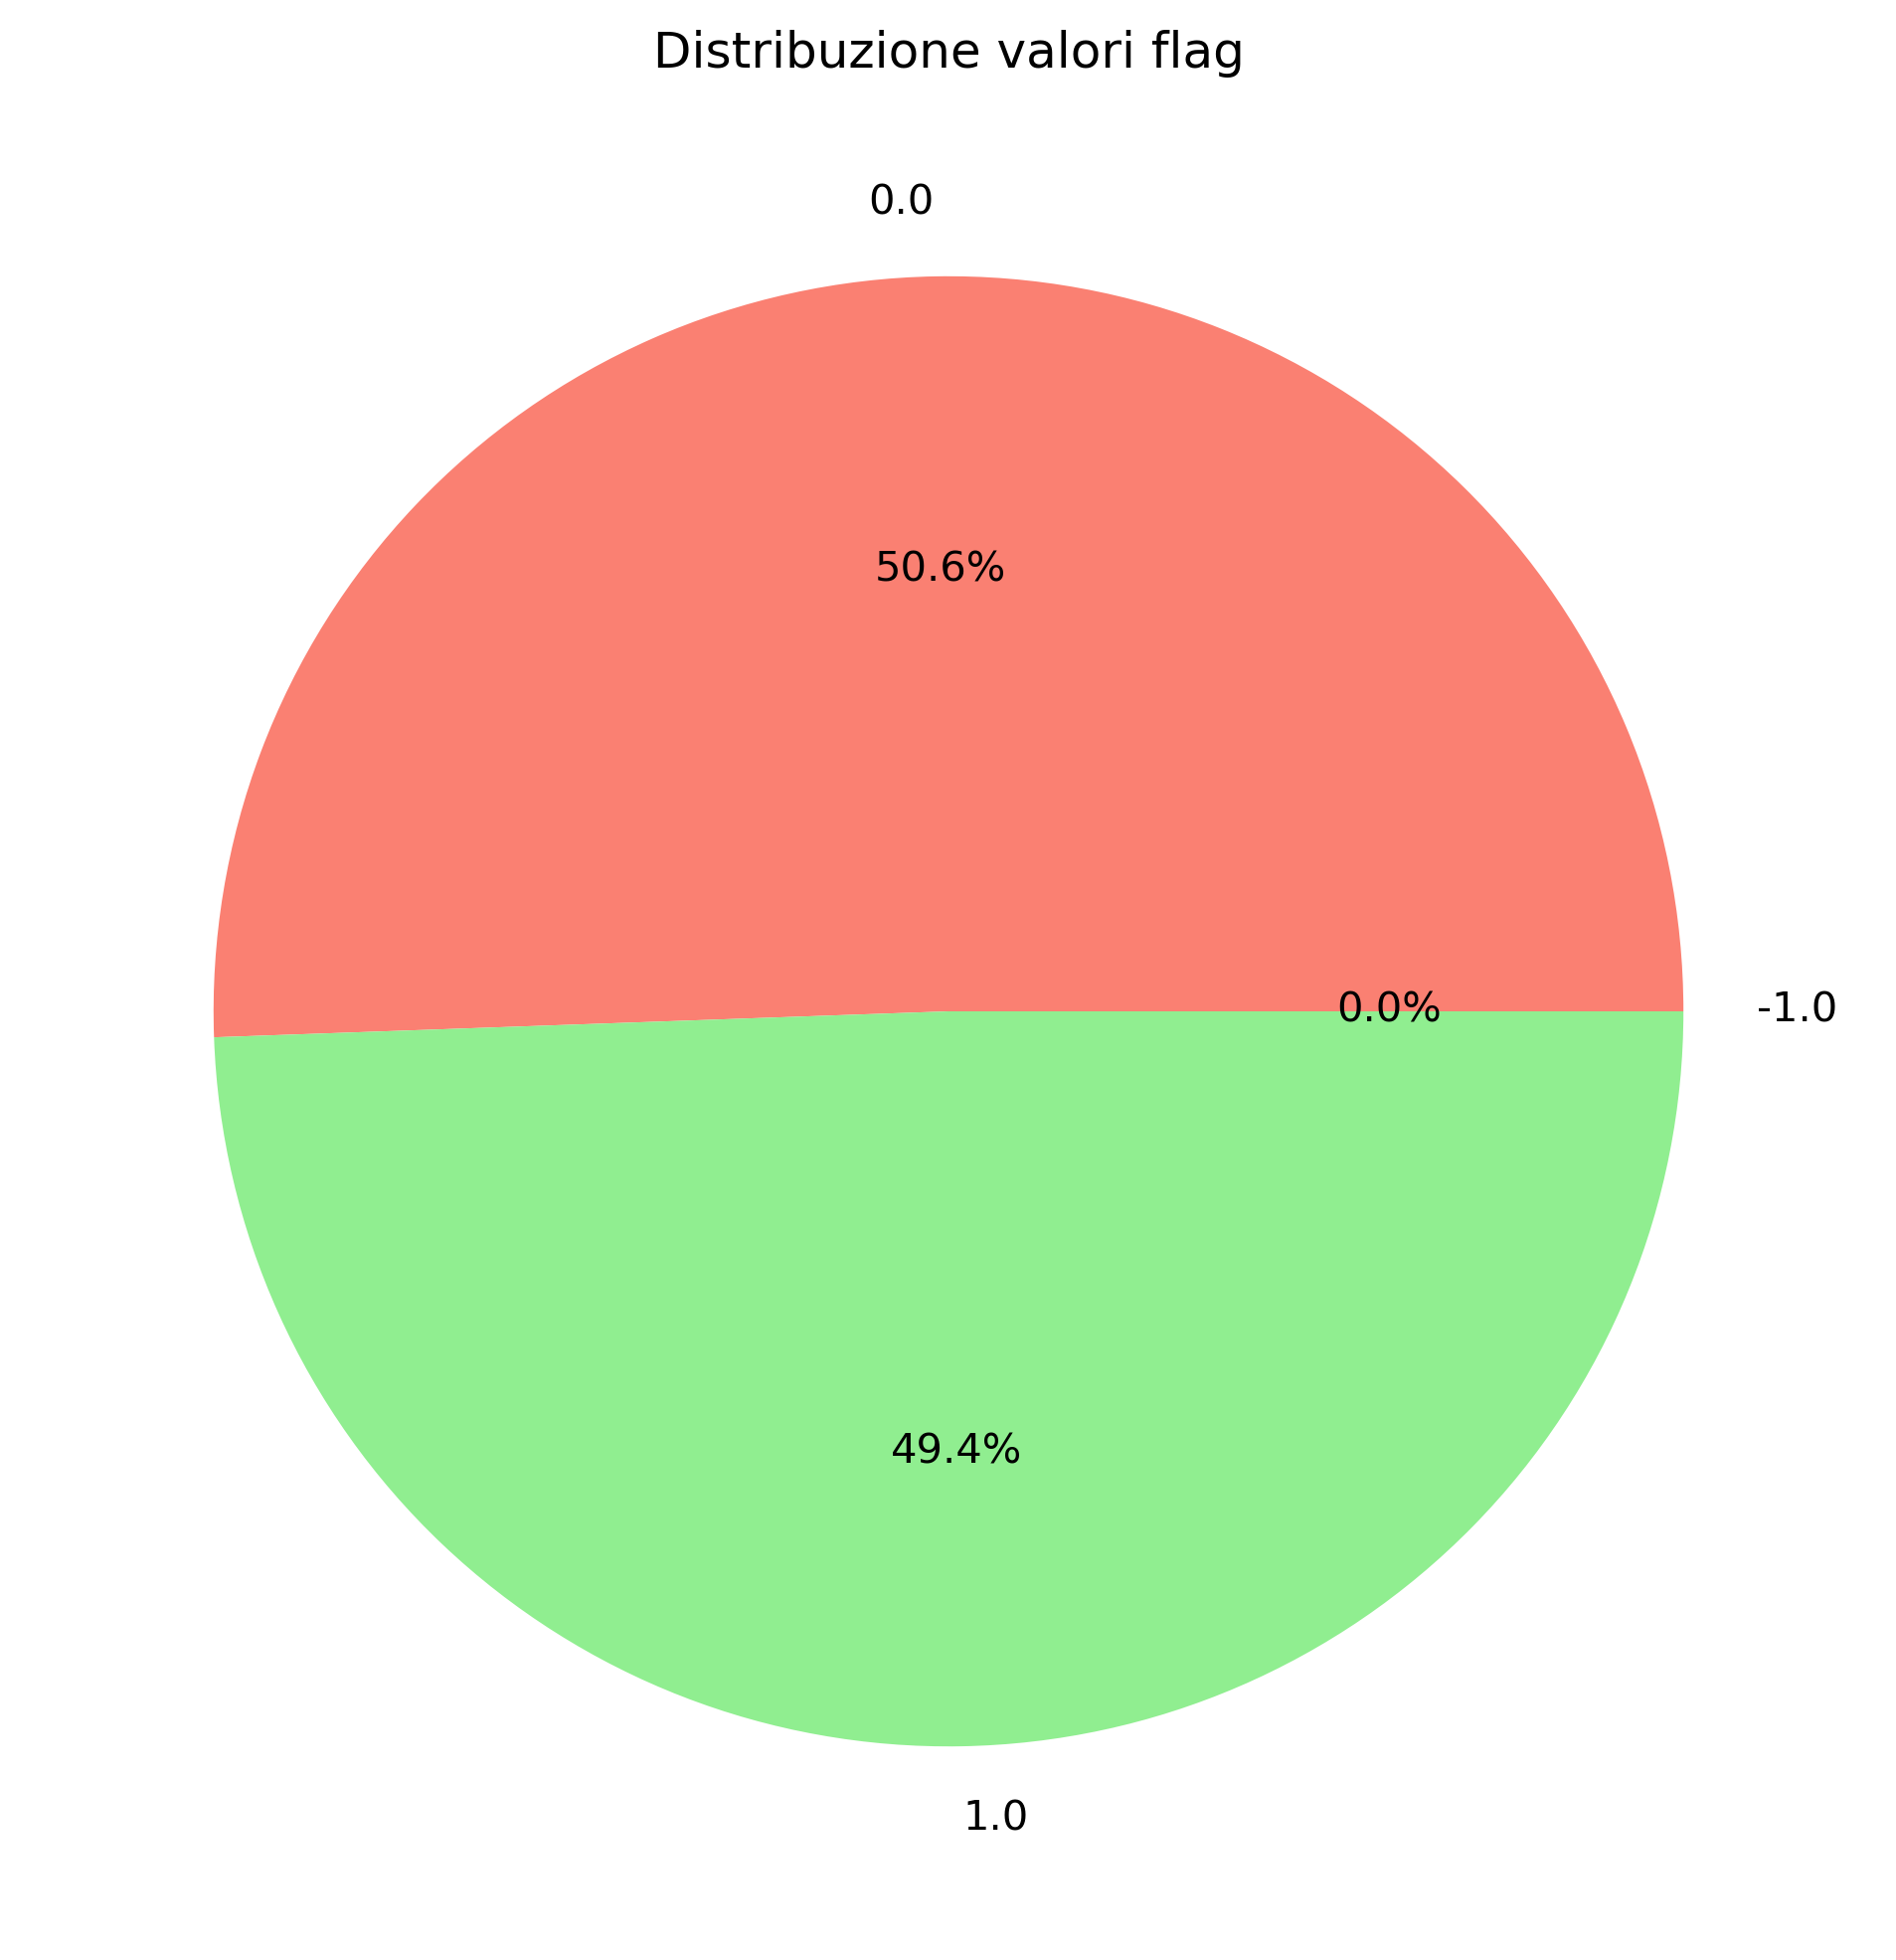

In [33]:
# Prima conta i valori della colonna flag
counts = joined_df['flag'].value_counts().sort_index()

# Poi crea il grafico a torta
plt.figure(figsize=(10, 8), dpi=300)
plt.pie(counts.values, 
        labels=counts.index,  # oppure ['Normale', 'Anormale']
        autopct='%1.1f%%',
        colors=['lightgreen', 'salmon'])
plt.title('Distribuzione valori flag')
plt.show()

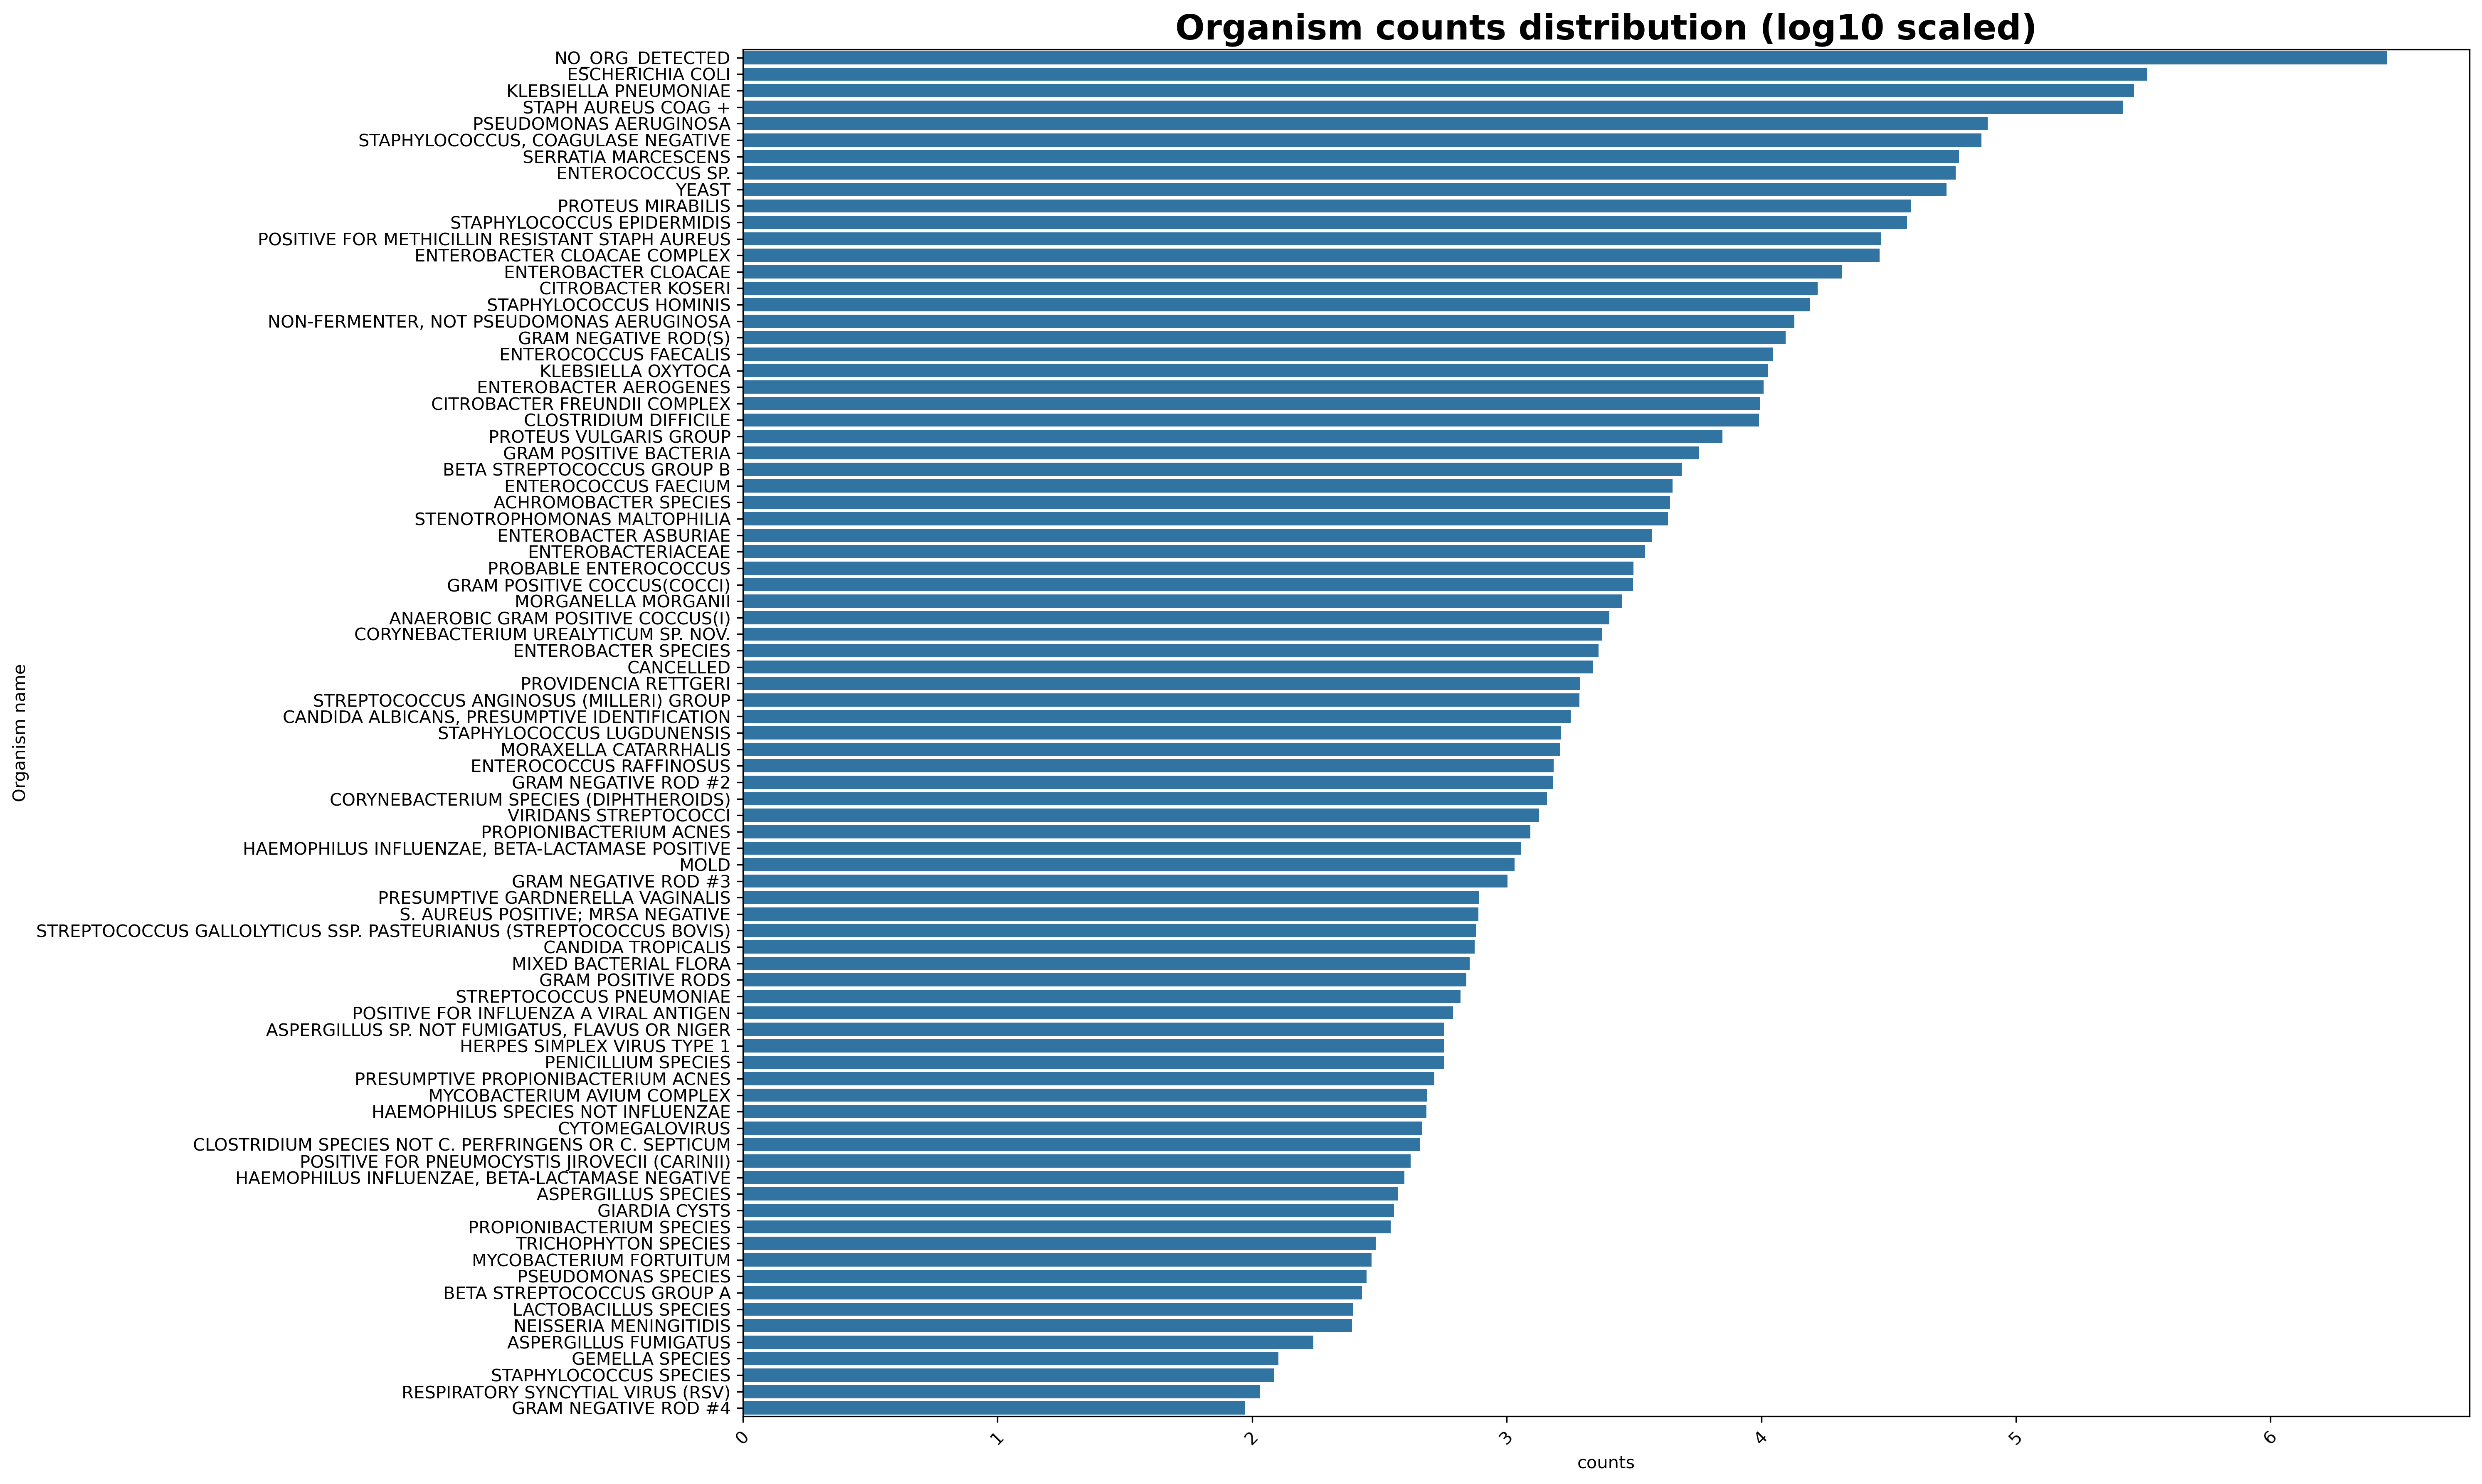

In [34]:
org_count = np.log10(joined_df['org_name'].value_counts().replace(0, np.nan))

plt.figure(figsize=(20, 12), dpi=300)
sns.barplot(y=org_count.index, x=org_count.values)
plt.title("Organism counts distribution (log10 scaled)", fontsize=20, fontweight="bold")
plt.ylabel("Organism name")
plt.xlabel("counts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

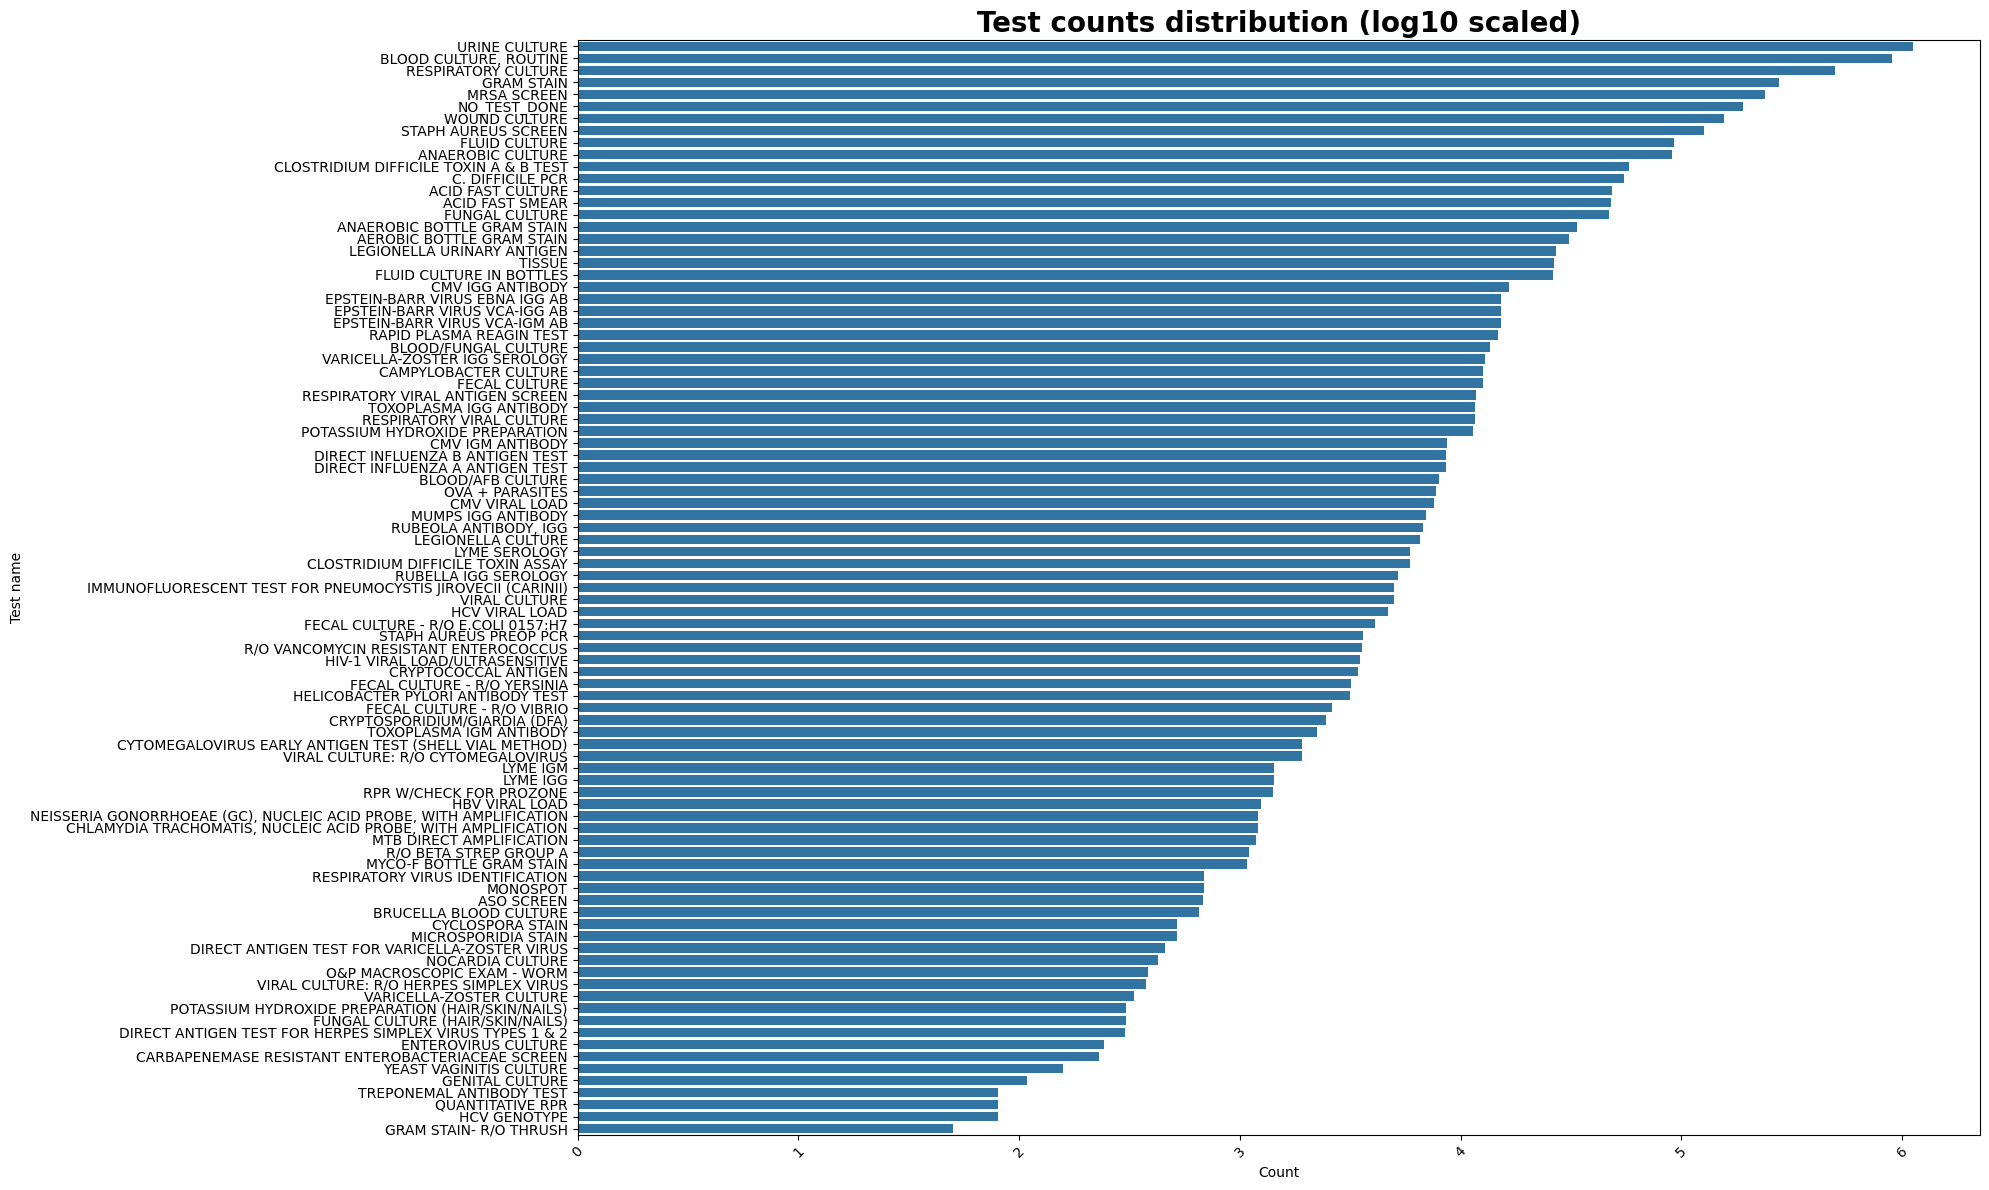

In [35]:
test_count = np.log10(joined_df['test_name'].value_counts().replace(0, np.nan))

plt.figure(figsize=(20, 12))
sns.barplot(y=test_count.index, x=test_count.values)
plt.title("Test counts distribution (log10 scaled)", fontsize=20, fontweight="bold")
plt.ylabel("Test name")
plt.xlabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

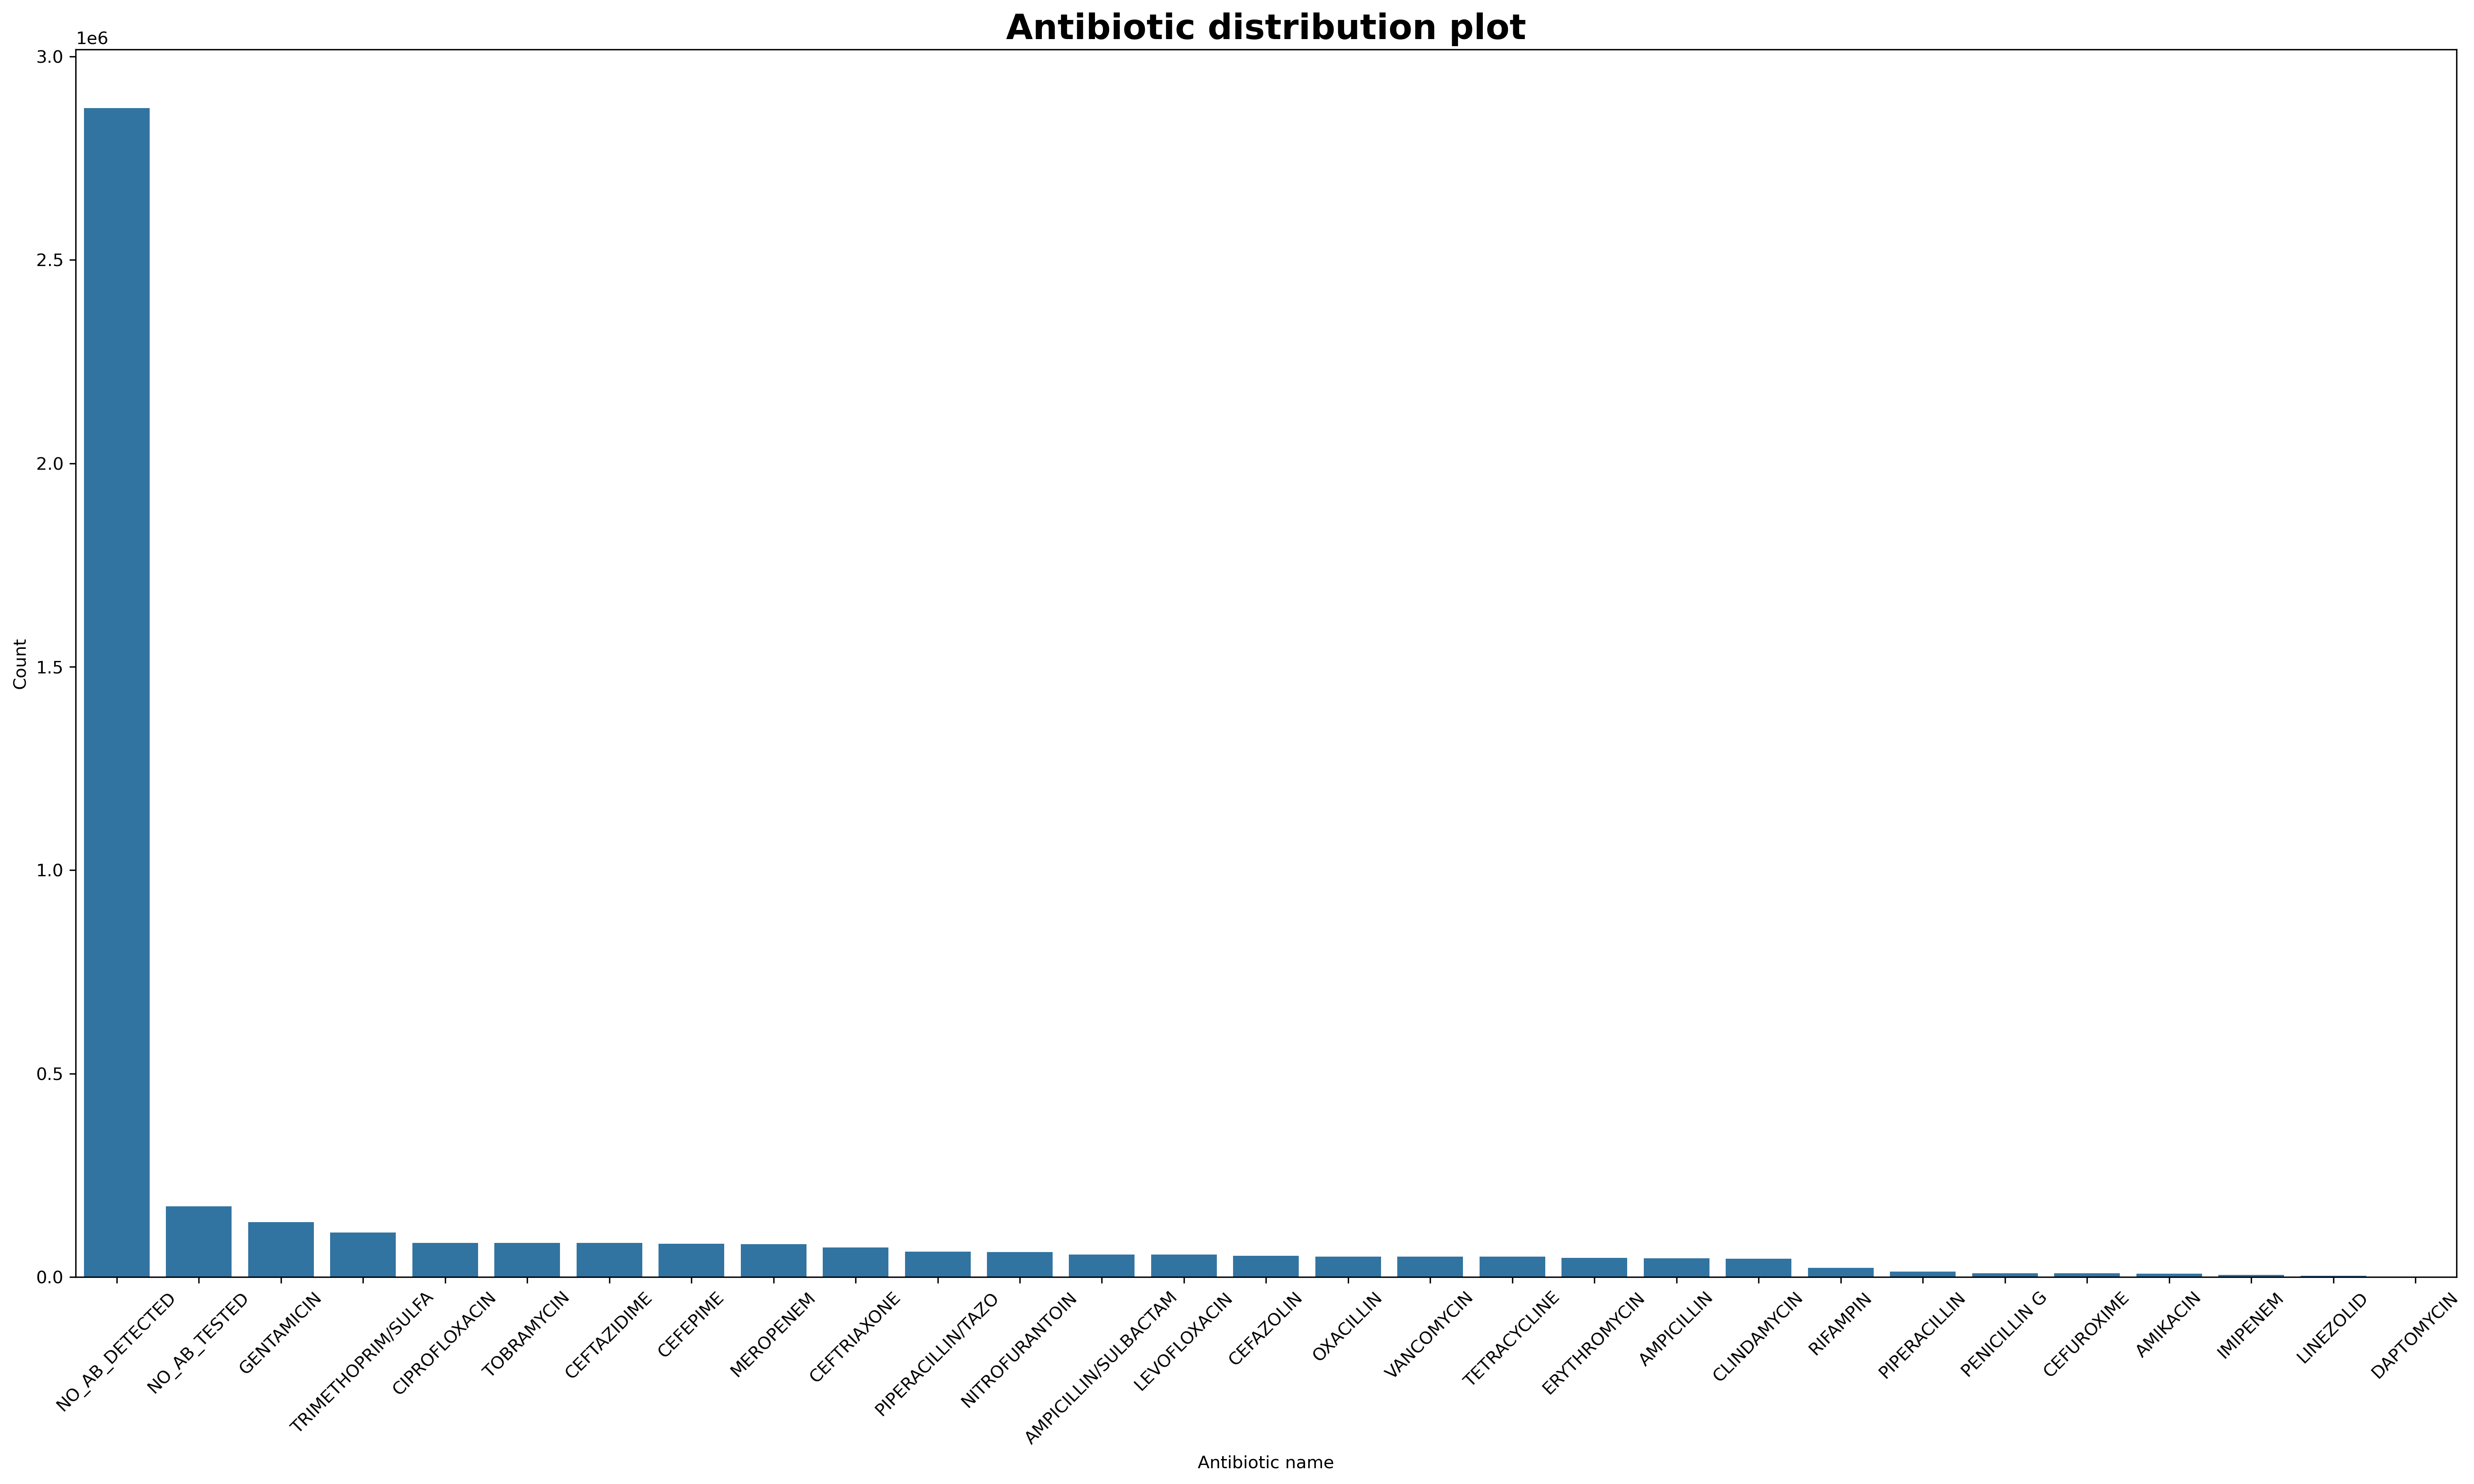

In [36]:
ab_count =joined_df['ab_name'].value_counts()

plt.figure(figsize=(20, 12), dpi=300)
sns.barplot(x=ab_count.index, y=ab_count.values)
plt.title("Antibiotic distribution plot", fontsize=20, fontweight="bold")
plt.xlabel("Antibiotic name")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

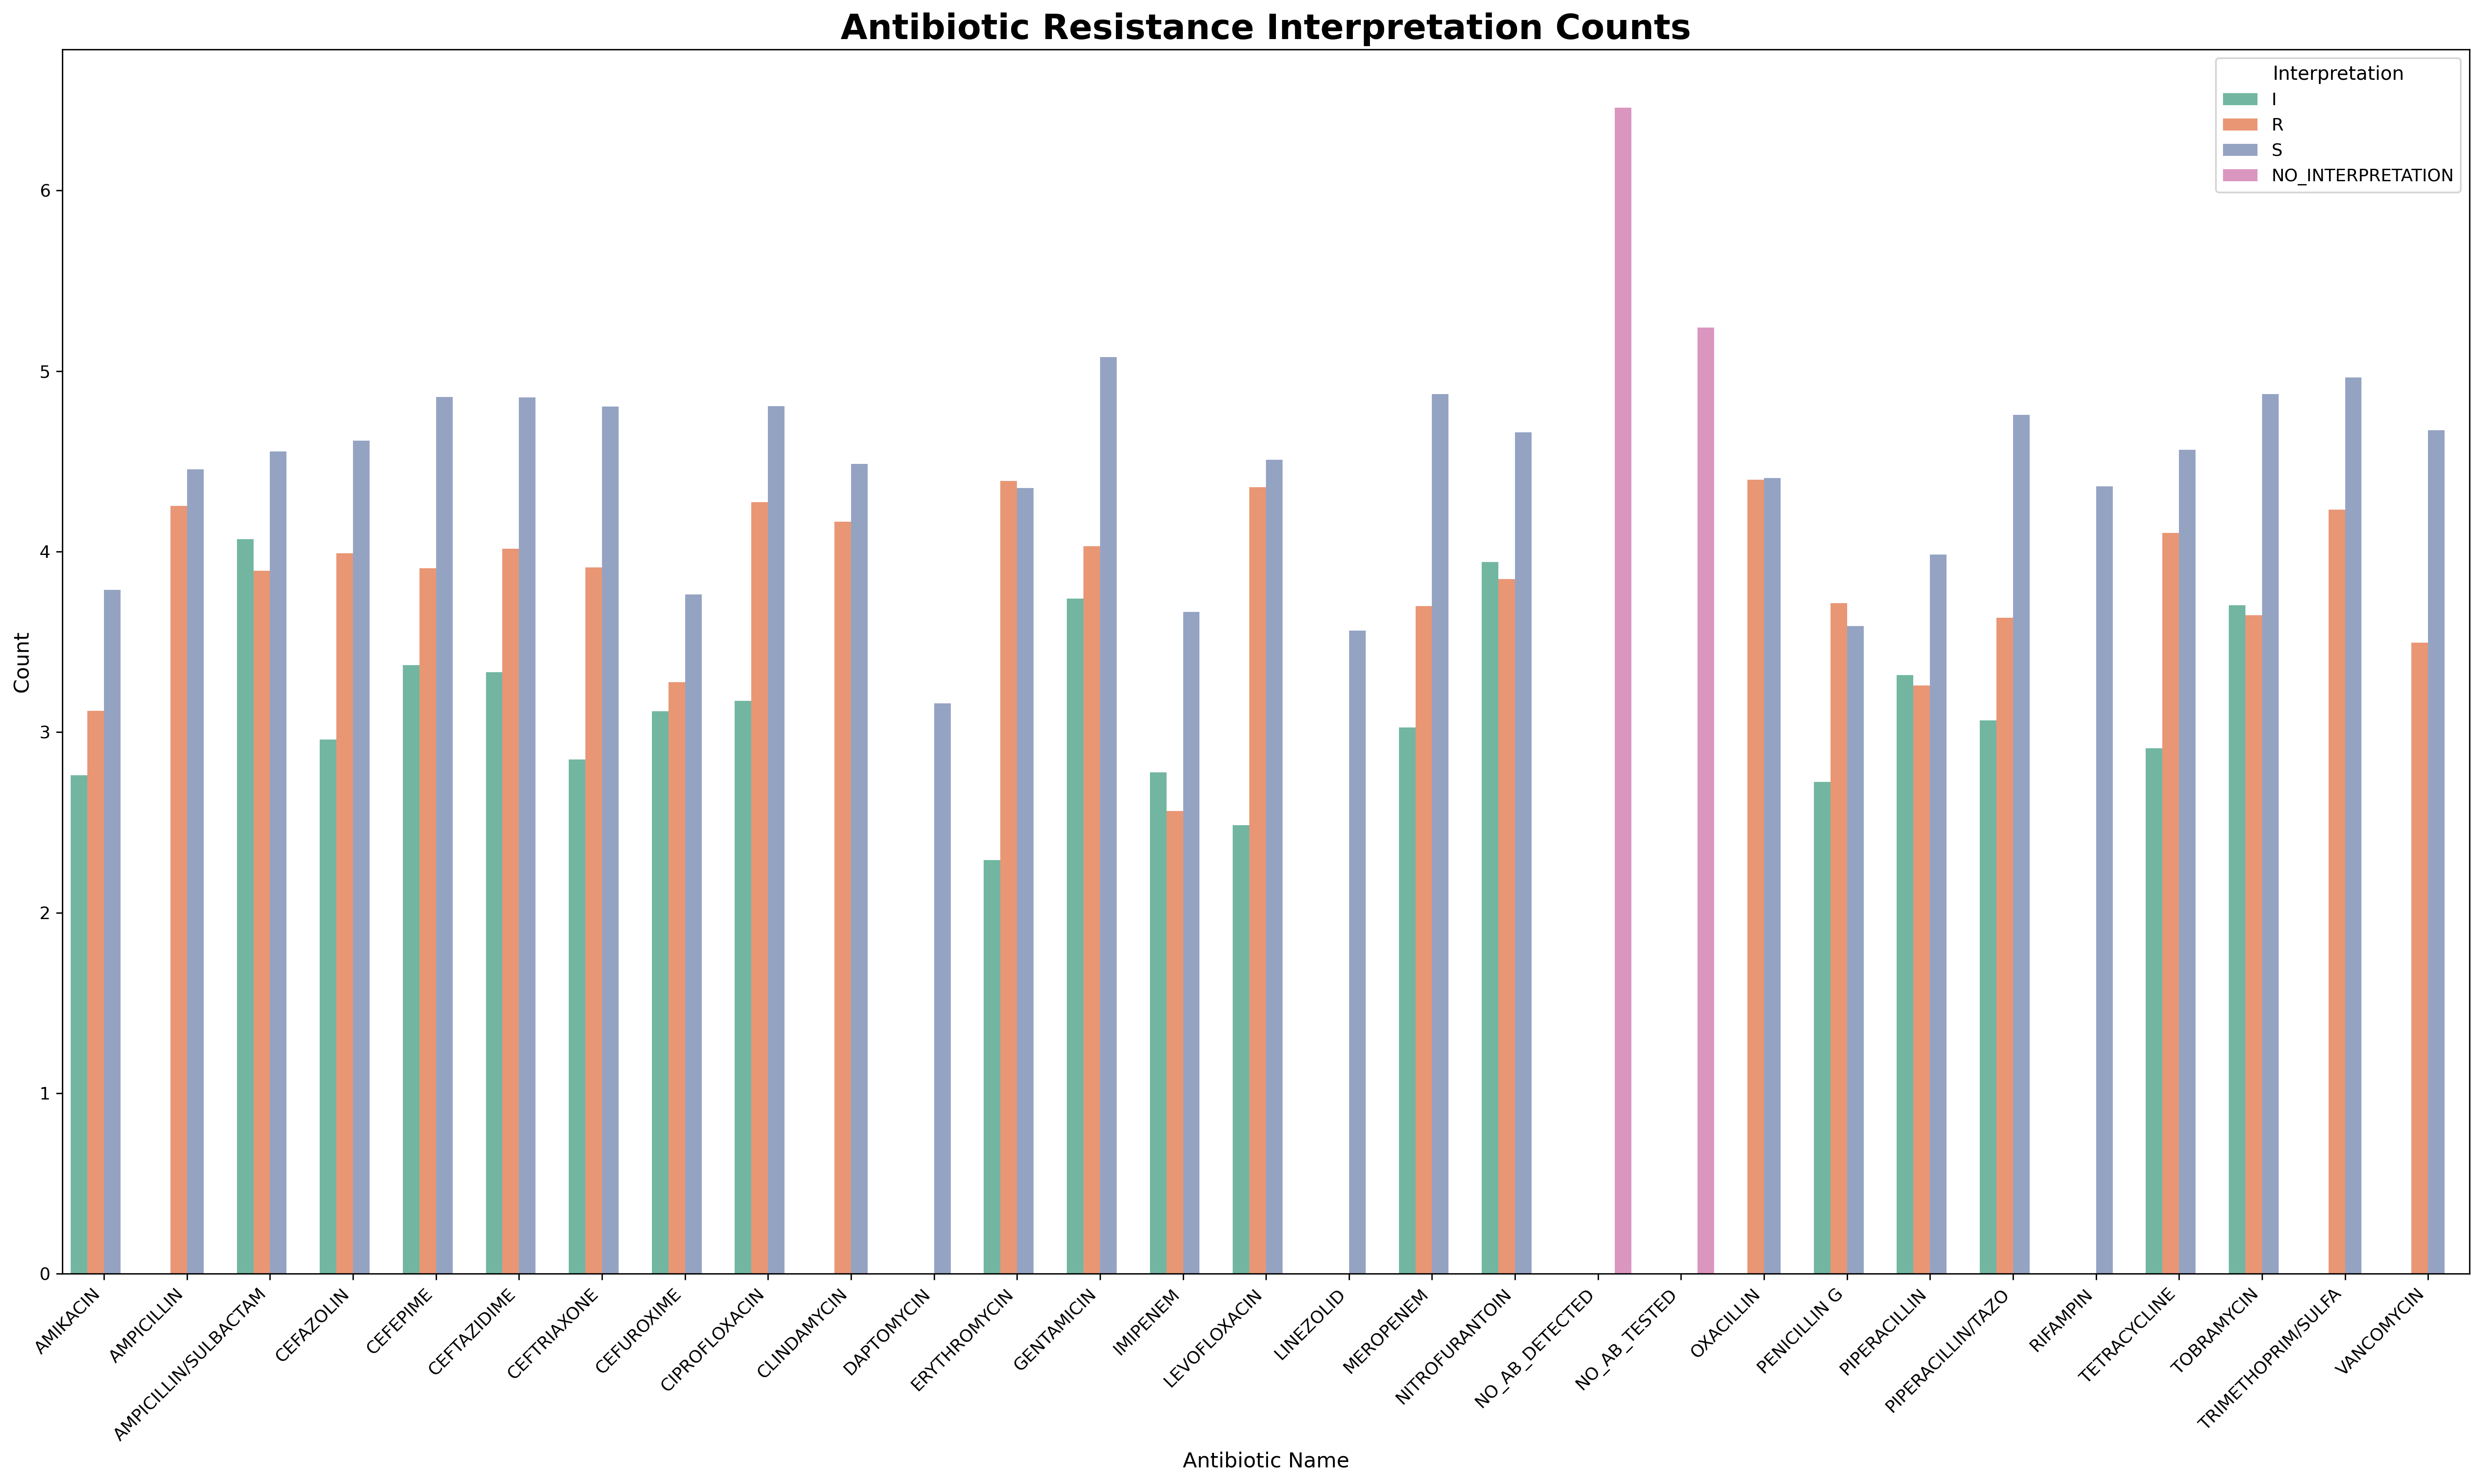

In [37]:
# Get the counts
resistant_counts = np.log10(joined_df.groupby("ab_name")['interpretation'].value_counts().replace(0, np.nan))
counts_df = resistant_counts.reset_index(name='count')

# Calculate average count for each interpretation to determine order
interpretation_avg = counts_df.groupby('interpretation')['count'].mean().sort_values(ascending=True)
sorted_interpretations = interpretation_avg.index.tolist()

# Create the plot
fig, ax = plt.subplots(figsize=(20,12), dpi=300)

# Create grouped barplot with sorted hue order
sns.barplot(
    data=counts_df,
    x='ab_name',
    y='count',
    hue='interpretation',
    ax=ax,
    palette='Set2',
    hue_order=sorted_interpretations
)

# Customize the plot
ax.set_title('Antibiotic Resistance Interpretation Counts', fontsize=20, fontweight='bold')
ax.set_xlabel('Antibiotic Name', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.legend(title='Interpretation', title_fontsize=11, fontsize=10)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

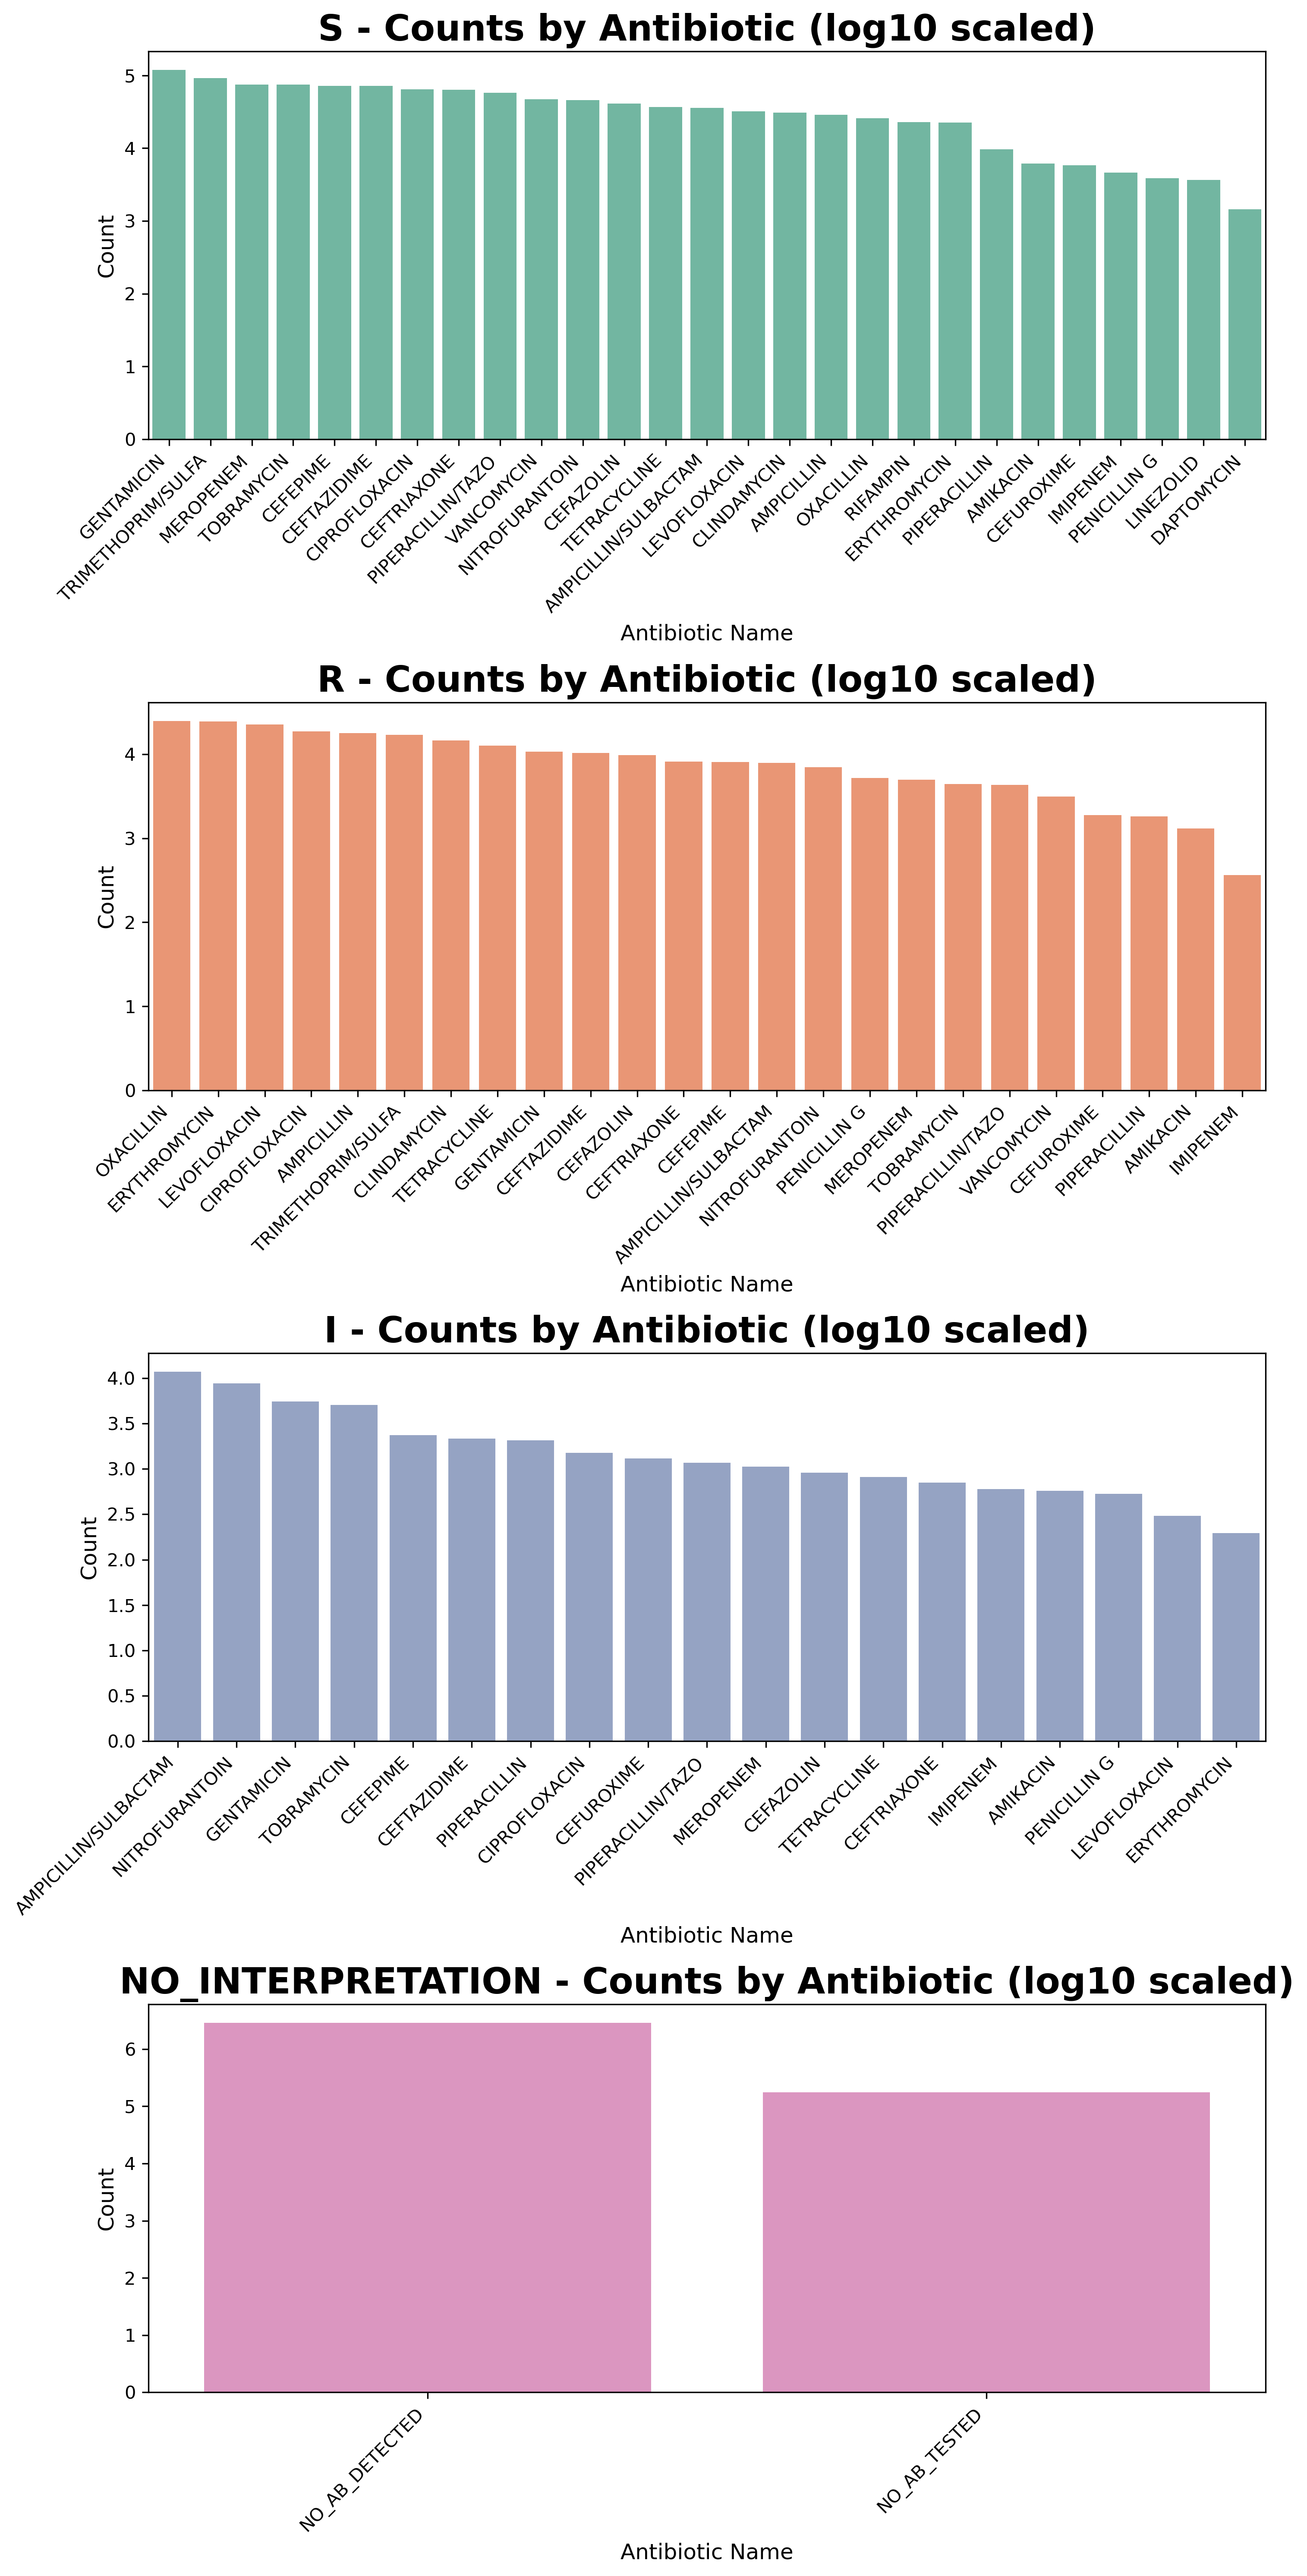

In [38]:
# Get unique interpretations
interpretations = counts_df['interpretation'].unique()
n_interpretations = len(interpretations)

# Create subplots - one for each interpretation
fig, axes = plt.subplots(n_interpretations, 1, figsize=(10,  5* n_interpretations), dpi=300)

# Handle case of single interpretation
if n_interpretations == 1:
    axes = [axes]

# Create a plot for each interpretation
for idx, interpretation in enumerate(interpretations):
    # Filter data for this interpretation
    subset = counts_df[counts_df['interpretation'] == interpretation]
    
    # Sort by count in descending order
    subset = subset.sort_values('count', ascending=False)
    
    # Create barplot
    sns.barplot(
        data=subset,
        x='ab_name',
        y='count',
        ax=axes[idx],
        color=sns.color_palette('Set2')[idx % 10],
        order=subset['ab_name']  # Explicitly set the order
    )
    
    # Customize the subplot
    axes[idx].set_title(f'{interpretation} - Counts by Antibiotic (log10 scaled)', 
                        fontsize=20, fontweight='bold')
    axes[idx].set_xlabel('Antibiotic Name', fontsize=12)
    axes[idx].set_ylabel('Count', fontsize=12)
    
    # Rotate x-axis labels
    axes[idx].tick_params(axis='x', rotation=45)
    plt.setp(axes[idx].xaxis.get_majorticklabels(), ha='right')

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()